# Planetary Defense with Machine Learning
### Decision trees vs neural networks for classifying potentially hazardous asteroids

CS Project 8 · Data: NASA JPL Small Body Database, downloaded 14 November 2026

Everything in this notebook (numbers, tables, figures) is produced by the code below. The data snapshot is saved in `data/`, so rerunning gives the same results. A full run takes about 6 minutes. Figures are saved to `figures/` and the main numbers to `results/results.json`.

## Summary

With MOID and H available, a depth 2 decision tree learns almost exactly the NASA rule for potentially hazardous asteroids (H ≤ 22.035 and MOID ≤ 0.0500 au, test F1 0.989), and deeper trees only add variance. A small network with 2 hidden neurons learns the same rule, with one neuron for each condition. When MOID is removed, the networks with 2 or 3 hidden layers do better than the best tree (F1 0.865 vs 0.778).

## 1 Introduction

NASA's Center for Near Earth Object Studies labels an asteroid a Potentially Hazardous Asteroid (PHA) when both of these hold (Center for Near Earth Object Studies, n.d.):

1. its Earth Minimum Orbit Intersection Distance (MOID) is 0.05 au or less (about 7.5 million km), and
2. its absolute magnitude H is 22.0 or less, which means it is roughly 140 m across or bigger.

Impacts are rare but they do happen. The Chelyabinsk airburst in 2013 injured more than 1,600 people (Popova et al., 2013; NASA Science Editorial Team, 2018), and in 2022 NASA's DART mission changed the orbit of the asteroid moonlet Dimorphos by about 33 minutes (Thomas et al., 2023).

We chose this dataset because the label comes from a published rule. Usually we can't tell if a model is using the right features, but here we know the answer, so we can check both the tree splits and the network weights against it. It also suits both methods. Two thresholds joined by AND is exactly what a decision tree does, while a network has to approximate the sharp corner with smooth functions. If MOID is removed, the label depends on the shape and orientation of the orbit, which might favor the networks.

Other work has used neural networks to find Earth impactors (Hefele et al., 2020) and to estimate MOID from orbital elements (Vichi and Tommei, 2025), and tree ensembles and other classifiers to label hazardous asteroids (Malakouti et al., 2023; Bora et al., 2024).

Questions we want to answer:
1. Does a decision tree find the rule, and how does max depth affect bias and variance?
2. Do all nodes at the same level split on the same attribute? Why or why not?
3. How do networks with different numbers of hidden layers and nodes compare?
4. Do the network edge weights line up with the tree splits?

In [1]:
# Setup: libraries, plotting style and output folders
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from scipy.stats import spearmanr
from joblib import Parallel, delayed
from IPython.display import display

import sklearn
from sklearn.exceptions import ConvergenceWarning, UndefinedMetricWarning
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             f1_score, precision_score, r2_score, recall_score, roc_auc_score)
from sklearn.model_selection import (StratifiedKFold, cross_val_predict, cross_validate,
                                     train_test_split)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

NOTEBOOK_START = time.time()
SEED = 42
DATA_DIR, FIG_DIR, RES_DIR = Path("data"), Path("figures"), Path("results")
for folder in (DATA_DIR, FIG_DIR, RES_DIR):
    folder.mkdir(exist_ok=True)

PHA_COLOR, SAFE_COLOR = "#c8102e", "#9aa5b1"     # hazardous red, neutral grey
POS_COLOR, NEG_COLOR = "#1f6fb2", "#e07b39"      # positive and negative network weights
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})
pd.set_option("display.precision", 4)
RESULTS = {}   # every number quoted in the text is stored here and saved at the end


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")


print(f"numpy {np.__version__} | pandas {pd.__version__} | sklearn {sklearn.__version__} | matplotlib {mpl.__version__}")

numpy 2.0.0 | pandas 2.3.3 | sklearn 1.7.2 | matplotlib 3.10.9


## 2 Dataset

### 2.1 Source

The data comes from the NASA JPL Small Body Database (SBDB) query API (NASA Jet Propulsion Laboratory, 2021). We download every near Earth asteroid (`sb-kind=a`, `sb-group=neo`) with full precision. A near Earth asteroid has a perihelion distance under 1.3 au. The first run downloads about 14 MB and saves it as a CSV; after that the saved file is used.

In [2]:
SBDB_URL = "https://ssd-api.jpl.nasa.gov/sbdb_query.api"
SBDB_FIELDS = ["spkid", "full_name", "pdes", "name", "neo", "pha", "H", "diameter", "albedo",
               "e", "a", "q", "i", "om", "w", "ma", "ad", "n", "per_y",
               "moid", "moid_ld", "moid_jup", "t_jup", "class", "epoch_cal",
               "condition_code", "data_arc", "n_obs_used", "first_obs", "last_obs", "rms"]
TEXT_FIELDS = {"spkid", "full_name", "pdes", "name", "neo", "pha", "class",
               "epoch_cal", "first_obs", "last_obs"}
CSV_PATH = DATA_DIR / "neo_asteroids_sbdb.csv"
META_PATH = DATA_DIR / "neo_asteroids_sbdb_meta.json"


def download_neo_asteroids():
    """Query the JPL Small Body Database for every near Earth asteroid and cache it as CSV."""
    import datetime as dt
    import requests
    params = {"fields": ",".join(SBDB_FIELDS), "sb-kind": "a", "sb-group": "neo", "full-prec": "true"}
    response = requests.get(SBDB_URL, params=params, timeout=180)
    response.raise_for_status()
    payload = response.json()
    table = pd.DataFrame(payload["data"], columns=payload["fields"])
    for col in table.columns:
        if col not in TEXT_FIELDS:
            table[col] = pd.to_numeric(table[col], errors="coerce")
    table["full_name"] = table["full_name"].str.strip()
    table.to_csv(CSV_PATH, index=False)
    meta = {"source": payload["signature"]["source"], "url": SBDB_URL, "params": params,
            "rows": len(table),
            "retrieved_utc": dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d %H:%M:%S UTC")}
    META_PATH.write_text(json.dumps(meta, indent=2))
    return table


raw = pd.read_csv(CSV_PATH, low_memory=False) if CSV_PATH.exists() else download_neo_asteroids()
raw["full_name"] = raw["full_name"].str.strip()
raw["pdes"] = raw["pdes"].astype(str)
meta = json.loads(META_PATH.read_text())
RESULTS["source"] = {"name": meta["source"], "retrieved_utc": meta["retrieved_utc"], "rows": len(raw)}
print(f"Source:    {meta['source']}")
print(f"Retrieved: {meta['retrieved_utc']}")
print(f"Shape:     {raw.shape[0]:,} asteroids x {raw.shape[1]} columns")
raw[["full_name", "H", "moid", "a", "e", "i", "q", "ad", "om", "w", "ma", "class", "pha"]].head()

Source:    NASA/JPL SBDB (Small-Body DataBase) Query API
Retrieved: 2026-11-14 19:27:07 UTC
Shape:     43,090 asteroids x 31 columns


,full_name,H,moid,a,e,i,q,ad,om,w,ma,class,pha
0,433 Eros (A898 PA),10.40,0.1488,1.4582,0.2229,10.8285,1.1332,1.7833,304.2680,178.9181,62.5115,AMO,N
1,719 Albert (A911 TB),15.59,0.2016,2.6369,0.5466,11.5724,1.1956,4.0783,183.8603,156.1760,286.6772,AMO,N
2,887 Alinda (A918 AA),13.82,0.0801,2.4740,0.5711,9.4000,1.0611,3.8869,110.4060,350.5494,132.1789,AMO,N
3,1036 Ganymed (A924 UB),9.17,0.3420,2.6641,0.5335,26.6877,1.2428,4.0854,215.3977,132.5073,142.9653,AMO,N
4,1221 Amor (1932 EA1),17.37,0.1090,1.9197,0.4347,11.8701,1.0852,2.7543,171.2356,26.7530,133.9761,AMO,N


### 2.2 Columns used

| Column | Meaning | Unit | Use |
|---|---|---|---|
| `pha` | PHA flag (Y or N) | | target |
| `moid` | smallest distance between the asteroid's orbit and Earth's orbit | au | input (Experiment A only) |
| `H` | absolute magnitude, smaller H means a bigger asteroid | mag | input |
| `a` | semimajor axis (size of the orbit) | au | input |
| `e` | eccentricity (0 is a circle) | | input |
| `i` | inclination to Earth's orbital plane | deg | input |
| `q` | perihelion distance (closest to the Sun) | au | input |
| `ad` | aphelion distance Q (farthest from the Sun) | au | input |
| `om` | longitude of the ascending node Ω | deg | input as sin and cos |
| `w` | argument of perihelion ω | deg | input as sin and cos |
| `ma` | mean anomaly M (where the asteroid is on its orbit right now) | deg | input as sin and cos, used as a control |
| `class` | orbit class (Apollo, Aten, Amor, Atira) | | not used as an input |
| `diameter`, `albedo` | measured size and reflectivity | | not used, missing for about 97% |

In [3]:
missing = raw[["H", "moid", "pha", "diameter", "albedo"]].isna().sum().rename("missing values")
data = raw.dropna(subset=["H", "moid", "pha"]).reset_index(drop=True).copy()
data["y"] = (data["pha"] == "Y").astype(int)
n_pha = int(data["y"].sum())
RESULTS["dataset"] = {
    "rows_raw": len(raw), "rows_clean": len(data), "rows_dropped": len(raw) - len(data),
    "n_pha": n_pha, "n_not_pha": int(len(data) - n_pha), "pha_share": n_pha / len(data),
    "diameter_known_share": float(raw["diameter"].notna().mean()),
}
display(missing.to_frame().T)
print(f"Kept {len(data):,} of {len(raw):,} asteroids ({len(raw) - len(data)} dropped for a missing H, MOID or label).")
print(f"PHA: {n_pha:,} ({n_pha / len(data):.2%})    not PHA: {len(data) - n_pha:,} ({1 - n_pha / len(data):.2%})")
print(f"A model that always answers 'not hazardous' would already score {1 - n_pha / len(data):.2%} accuracy.")

orbit_names = {"APO": "Apollo (Earth crossing, a > 1 au)", "ATE": "Aten (Earth crossing, a < 1 au)",
               "AMO": "Amor (outside Earth, 1.017 < q < 1.3 au)", "IEO": "Atira (inside Earth's orbit)"}
by_class = data.assign(orbit_class=data["class"].map(orbit_names)).groupby("orbit_class")["y"].agg(asteroids="size", PHAs="sum")
by_class["PHA share"] = (by_class["PHAs"] / by_class["asteroids"]).map("{:.1%}".format)
by_class.sort_values("asteroids", ascending=False)

,H,moid,pha,diameter,albedo
missing values,9,135,135,41844,41886


Kept 42,953 of 43,090 asteroids (137 dropped for a missing H, MOID or label).
PHA: 2,552 (5.94%)    not PHA: 40,401 (94.06%)
A model that always answers 'not hazardous' would already score 94.06% accuracy.


,asteroids,PHAs,PHA share
orbit_class,,,
"Apollo (Earth crossing, a > 1 au)",24447,2189,9.0%
"Amor (outside Earth, 1.017 < q < 1.3 au)",14974,156,1.0%
"Aten (Earth crossing, a < 1 au)",3493,199,5.7%
Atira (inside Earth's orbit),39,8,20.5%


### 2.3 Does the label match the published rule?

In [4]:
rule = (data["moid"] <= 0.05) & (data["H"] <= 22.0)
agree = rule == (data["y"] == 1)
disagree = data.loc[~agree, ["full_name", "H", "moid", "pha", "condition_code"]]
RESULTS["rule_check"] = {
    "agree": int(agree.sum()), "agree_share": float(agree.mean()), "disagree": int((~agree).sum()),
    "labelled_pha_rule_says_no": int(((data["y"] == 1) & ~rule).sum()),
    "labelled_not_rule_says_pha": int(((data["y"] == 0) & rule).sum()),
    "disagree_H_min": float(disagree["H"].min()), "disagree_H_max": float(disagree["H"].max()),
    "all_disagreements_have_moid_ok": bool((disagree["moid"] <= 0.05).all()),
}
table = pd.crosstab(rule.map({True: "rule says PHA", False: "rule says not PHA"}),
                    data["pha"].map({"Y": "label PHA", "N": "label not PHA"}))
display(table)
rc = RESULTS["rule_check"]
print(f"Agreement: {rc['agree']:,} of {len(data):,} asteroids ({rc['agree_share']:.2%}); {rc['disagree']} disagree.")
print(f"All disagreements have MOID <= 0.05 au: {rc['all_disagreements_have_moid_ok']}. "
      f"Their H values run from {rc['disagree_H_min']:.2f} to {rc['disagree_H_max']:.2f}, right at the H = 22 boundary.")
disagree.sort_values("H").head(8)

pha,label PHA,label not PHA
row_0,,
rule says PHA,2520,17
rule says not PHA,32,40384


Agreement: 42,904 of 42,953 asteroids (99.89%); 49 disagree.
All disagreements have MOID <= 0.05 au: True. Their H values run from 21.70 to 22.57, right at the H = 22 boundary.


,full_name,H,moid,pha,condition_code
20448,(2019 KD7),21.70,0.0341,N,8.0
37808,(2025 EZ3),21.90,0.0177,N,6.0
9662,(2012 KN11),21.90,0.0205,N,7.0
39122,(2025 RY1),21.95,0.0122,N,4.0
13858,(2015 XA352),21.98,0.0444,N,0.0
23926,(2020 SH2),21.99,0.0465,N,0.0
3594,853358 (2009 DL46),21.99,0.0123,N,0.0
7072,(2008 XM1),22.00,0.0031,N,0.0


The flag matches the rule for 42,904 of 42,953 asteroids (99.89%). All 49 mismatches have MOID under 0.05 au and H between 21.70 and 22.57, so they are right at the size cutoff (32 are flagged with H just over 22, and 17 are not flagged with H at or just under 22). Most likely the flag and the latest H estimate are slightly out of sync, so we left these in as label noise.

### 2.4 Exploration

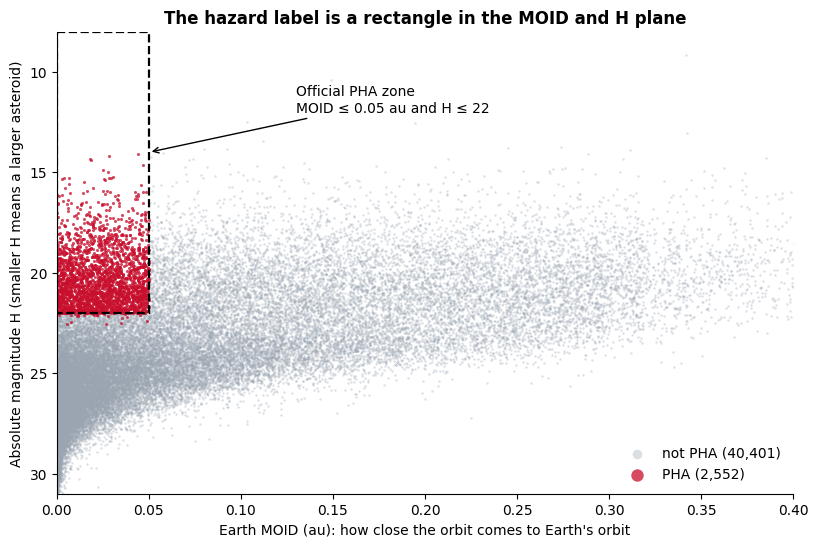

In [5]:
fig, ax = plt.subplots(figsize=(9.5, 6))
safe, haz = data[data["y"] == 0], data[data["y"] == 1]
ax.scatter(safe["moid"], safe["H"], s=3, c=SAFE_COLOR, alpha=0.35, linewidths=0,
           label=f"not PHA ({len(safe):,})", rasterized=True)
ax.scatter(haz["moid"], haz["H"], s=5, c=PHA_COLOR, alpha=0.75, linewidths=0,
           label=f"PHA ({len(haz):,})", rasterized=True)
ax.add_patch(Rectangle((0, 8), 0.05, 14, fill=False, ec="black", lw=1.6, ls="--"))
ax.annotate("Official PHA zone\nMOID ≤ 0.05 au and H ≤ 22", xy=(0.05, 14), xytext=(0.13, 12),
            arrowprops=dict(arrowstyle="->", color="black"), fontsize=10)
ax.set_xlim(0, 0.4)
ax.set_ylim(31, 8)    # inverted so that larger (brighter) asteroids sit at the top
ax.set_xlabel("Earth MOID (au): how close the orbit comes to Earth's orbit")
ax.set_ylabel("Absolute magnitude H (smaller H means a larger asteroid)")
ax.set_title("The hazard label is a rectangle in the MOID and H plane")
ax.legend(loc="lower right", markerscale=4, frameon=False)
savefig(fig, "fig01_hazard_zone")
plt.show()

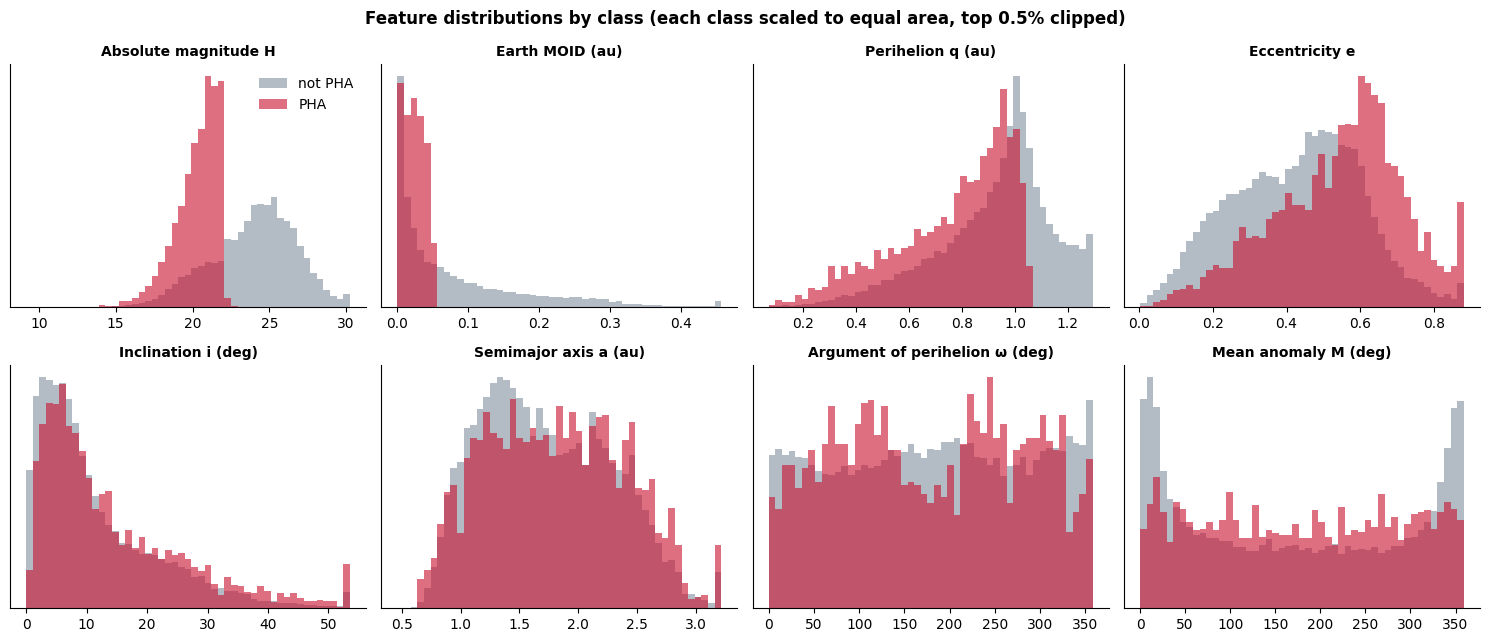

In [6]:
plot_cols = [("H", "Absolute magnitude H"), ("moid", "Earth MOID (au)"), ("q", "Perihelion q (au)"),
             ("e", "Eccentricity e"), ("i", "Inclination i (deg)"), ("a", "Semimajor axis a (au)"),
             ("w", "Argument of perihelion ω (deg)"), ("ma", "Mean anomaly M (deg)")]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, (col, label) in zip(axes.ravel(), plot_cols):
    values = data[col].clip(upper=data[col].quantile(0.995))
    bins = np.linspace(values.min(), values.max(), 50)
    ax.hist(values[data["y"] == 0], bins=bins, density=True, color=SAFE_COLOR, alpha=0.75, label="not PHA")
    ax.hist(values[data["y"] == 1], bins=bins, density=True, color=PHA_COLOR, alpha=0.6, label="PHA")
    ax.set_title(label, fontsize=10)
    ax.set_yticks([])
axes[0, 0].legend(frameon=False)
fig.suptitle("Feature distributions by class (each class scaled to equal area, top 0.5% clipped)", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig02_feature_distributions")
plt.show()

In Figure 1 the PHAs fill the box MOID ≤ 0.05 au and H ≤ 22 and almost nothing else. Most known near Earth asteroids are small (median H = 24.1, about 50 m), since small ones are only found when they pass close to Earth.

In Figure 2, H, MOID and q separate the two classes the most. No PHA has q above 1.064 au, because an orbit that never gets closer to the Sun than about 1.067 au (Earth's farthest point plus 0.05 au) can't get within 0.05 au of Earth's orbit. PHAs also tend to have higher eccentricity. The control variable M is not completely flat for non PHAs, with peaks near 0° and 360° (near perihelion). Our guess is that this comes from how asteroids are discovered, not from physics.

## 3 Analysis technique

### 3.1 Inputs

Both model types get the same inputs: MOID, H, a, e, i, q, Q, and the sine and cosine of Ω, ω and M. M is a control and shouldn't matter. Angles are given as sine and cosine so that 359° and 1° are close together. The trees use the raw values, since trees don't care about scaling and the thresholds stay readable. For the networks we take log10 of a and Q (they have long tails, up to 354 au and 706 au) and then standardize everything.

### 3.2 Experiments

1. **A:** all 13 inputs, MOID included.
2. **B:** MOID removed (12 inputs), so the models have to work out from the orbit how close it gets to Earth's orbit.
3. **C:** B plus three extra features: the distance from the Sun of the two orbital nodes (where the orbit crosses Earth's orbital plane) and how far the closer node is from 1 au.

### 3.3 Split and metrics

We use one stratified 80/20 train/test split (seed 42) for every model. Tree depth is chosen with 5 fold cross validation on the training set. Only about 6% of the asteroids are PHAs, so always guessing "not PHA" already gets 94% accuracy. Because of that we mainly look at F1 for the PHA class, and also report balanced accuracy, ROC AUC and average precision.

### 3.4 Decision trees

We use sklearn's `DecisionTreeClassifier` (Pedregosa et al., 2011), which implements CART (Breiman et al., 1984/2017). At each node it tries every input and threshold and keeps the split that lowers Gini impurity the most. We try `max_depth` = 1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20 and no limit, and draw the trees with `plot_tree` like in class.

### 3.5 Bias and variance

Deeper trees fit the training data better (lower bias) but change more depending on the training sample (higher variance) (Geman et al., 1992; Hastie et al., 2009). To actually measure this we train 31 trees per depth on bootstrap samples of the training set and use the 0/1 loss decomposition from Domingos (2000):

* the main prediction for a test asteroid is the majority vote of the 31 trees,
* bias is 1 if the majority vote is wrong,
* variance is the fraction of trees that disagree with the majority.

With two classes, error = bias + (variance where the vote is right) − (variance where the vote is wrong). We used 31 trees so there are no ties in the vote.

### 3.6 Neural networks

We use sklearn's `MLPClassifier` with ReLU, the Adam optimizer (Kingma and Ba, 2015), learning rate 0.001, L2 penalty 0.0001, batch size 200 and up to 1,000 epochs. Each architecture is trained with 5 random seeds and we report the mean and standard deviation. The plots show the seed 0 network.

| Name | Hidden layers | Nodes per layer |
|---|---|---|
| Tiny | 1 | 2 |
| Small | 1 | 8 |
| Medium | 2 | 16, 8 |
| Deep | 3 | 32, 16, 8 |

In theory a big enough network can approximate any continuous function (Hornik et al., 1989), so the question is how big it needs to be for this problem. To draw the networks we wrote a small matplotlib function that shows every node and edge, with the edge color showing the sign of the weight and the thickness showing its size. Tools like LeNail's (2019) only draw the layout, and we wanted to see the trained weights.

### 3.7 Comparing weights with the tree

For the tree we use Gini importance and permutation importance. For the networks we use:

1. the sum of absolute first layer weights for each input (Garson, 1991),
2. Olden's connection weights, where the weight matrices are multiplied through the network (Olden and Jackson, 2002; Olden et al., 2004),
3. permutation importance, which works the same way for any model (Breiman, 2001; Fisher et al., 2019).

We compare them with Spearman's rank correlation ρ. We also check how each hidden neuron's activation correlates with MOID and H.

In [7]:
# Inputs shared by both model families
for angle in ["om", "w", "ma"]:
    radians = np.radians(data[angle])
    data[f"sin_{angle}"], data[f"cos_{angle}"] = np.sin(radians), np.cos(radians)

# Physics hint for Experiment C: Sun distance of the ascending and descending nodes
orbit_p = data["a"] * (1 - data["e"] ** 2)                  # orbit parameter p = a(1 - e^2)
cos_w = np.cos(np.radians(data["w"]))
data["r_asc"] = orbit_p / (1 + data["e"] * cos_w)            # node where the orbit climbs through the ecliptic
data["r_desc"] = orbit_p / (1 - data["e"] * cos_w)           # node where it descends
data["node_gap"] = np.minimum((data["r_asc"] - 1).abs(), (data["r_desc"] - 1).abs())

ANGLES = ["sin_om", "cos_om", "sin_w", "cos_w", "sin_ma", "cos_ma"]
ORBIT = ["H", "a", "e", "i", "q", "ad"] + ANGLES
FEATURES = {"A": ["moid"] + ORBIT,                           # full information
            "B": ORBIT,                                      # MOID hidden
            "C": ORBIT + ["r_asc", "r_desc", "node_gap"]}    # MOID hidden plus physics hint
LOG_COLS = ["a", "ad", "r_asc", "r_desc", "node_gap"]        # long tailed, log scaled for networks only
NICE = {"moid": "MOID", "H": "H", "a": "a", "e": "e", "i": "i", "q": "q", "ad": "Q",
        "sin_om": "sin Ω", "cos_om": "cos Ω", "sin_w": "sin ω", "cos_w": "cos ω",
        "sin_ma": "sin M", "cos_ma": "cos M", "r_asc": "r asc", "r_desc": "r desc", "node_gap": "node gap"}

idx_train, idx_test = train_test_split(np.arange(len(data)), test_size=0.2,
                                       stratify=data["y"], random_state=SEED)
y_train, y_test = data["y"].values[idx_train], data["y"].values[idx_test]


def X(exp, rows):
    """Input table for experiment A, B or C on the given rows."""
    return data.loc[rows, FEATURES[exp]]


RESULTS["split"] = {"train": len(idx_train), "test": len(idx_test),
                    "train_pha": int(y_train.sum()), "test_pha": int(y_test.sum()),
                    "inputs": {k: len(v) for k, v in FEATURES.items()}}
print(f"Training set: {len(idx_train):,} asteroids ({y_train.sum():,} PHAs)")
print(f"Test set:     {len(idx_test):,} asteroids ({y_test.sum():,} PHAs)")
print({k: [NICE[c] for c in v] for k, v in FEATURES.items()})

Training set: 34,362 asteroids (2,042 PHAs)
Test set:     8,591 asteroids (510 PHAs)
{'A': ['MOID', 'H', 'a', 'e', 'i', 'q', 'Q', 'sin Ω', 'cos Ω', 'sin ω', 'cos ω', 'sin M', 'cos M'], 'B': ['H', 'a', 'e', 'i', 'q', 'Q', 'sin Ω', 'cos Ω', 'sin ω', 'cos ω', 'sin M', 'cos M'], 'C': ['H', 'a', 'e', 'i', 'q', 'Q', 'sin Ω', 'cos Ω', 'sin ω', 'cos ω', 'sin M', 'cos M', 'r asc', 'r desc', 'node gap']}


In [8]:
# Shared helpers: metrics and decision tree tools
def score_all(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"accuracy": accuracy_score(y_true, pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, proba),
            "avg_precision": average_precision_score(y_true, proba)}


DEPTHS = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def depth_label(depth):
    return "none" if depth is None else depth


def depth_sweep(exp):
    """Cross validated and test scores of trees of every depth."""
    Xtr, Xte = X(exp, idx_train), X(exp, idx_test)
    rows = []
    for depth in DEPTHS:
        tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
        cv = cross_validate(tree, Xtr, y_train, cv=CV, scoring=["accuracy", "f1"],
                            return_train_score=True, n_jobs=-1)
        tree.fit(Xtr, y_train)
        test = score_all(y_test, tree.predict_proba(Xte)[:, 1])
        rows.append({"max_depth": depth_label(depth), "leaves": tree.get_n_leaves(),
                     "train_acc": cv["train_accuracy"].mean(), "cv_acc": cv["test_accuracy"].mean(),
                     "train_f1": cv["train_f1"].mean(), "cv_f1": cv["test_f1"].mean(),
                     "cv_f1_std": cv["test_f1"].std(), "test_acc": test["accuracy"],
                     "test_f1": test["f1"], "test_auc": test["roc_auc"], "test_ap": test["avg_precision"]})
    return pd.DataFrame(rows)


def pick_depth(sweep):
    """Depth with the best cross validated F1 (ties go to the shallower tree)."""
    best = sweep["cv_f1"].max()
    label = sweep.loc[sweep["cv_f1"] >= best - 1e-12, "max_depth"].iloc[0]
    return None if label == "none" else int(label)


def fit_tree(exp, depth):
    return DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(X(exp, idx_train), y_train)


def show_tree(tree, exp, title, fname, figsize, fontsize=9):
    fig, ax = plt.subplots(figsize=figsize)
    plot_tree(tree, feature_names=[NICE[c] for c in FEATURES[exp]], class_names=["not PHA", "PHA"],
              filled=True, rounded=True, impurity=True, precision=4, fontsize=fontsize, ax=ax)
    ax.set_title(title, fontsize=14)
    savefig(fig, fname)
    plt.show()


def splits_by_level(tree, exp):
    """Every internal node with its level, split attribute, threshold and PHA share."""
    t, names = tree.tree_, FEATURES[exp]
    level = {0: 0}
    rows = []
    for node in range(t.node_count):
        left, right = t.children_left[node], t.children_right[node]
        if left == right:      # leaf
            continue
        level[left] = level[right] = level[node] + 1
        counts = t.value[node][0]
        rows.append({"level": level[node], "node": node, "split on": NICE[names[t.feature[node]]],
                     "threshold": round(float(t.threshold[node]), 4), "asteroids": int(t.n_node_samples[node]),
                     "PHA share": counts[1] / counts.sum(), "Gini": t.impurity[node]})
    return pd.DataFrame(rows)


def best_gain_per_feature(Xdf, y):
    """For each input, the best single split and how much it lowers Gini impurity."""
    rows = []
    for col in Xdf.columns:
        stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(Xdf[[col]], y)
        t = stump.tree_
        if t.node_count < 3:
            rows.append({"input": NICE[col], "best threshold": np.nan, "Gini decrease": 0.0})
            continue
        n = t.n_node_samples
        child = (n[1] * t.impurity[1] + n[2] * t.impurity[2]) / n[0]
        rows.append({"input": NICE[col], "best threshold": t.threshold[0], "Gini decrease": t.impurity[0] - child})
    return pd.DataFrame(rows).sort_values("Gini decrease", ascending=False).reset_index(drop=True)


def _boot_predict(depth, Xtr, ytr, Xte, b):
    return DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(Xtr[b], ytr[b]).predict(Xte)


def bias_variance(exp, n_boot=31):
    """Domingos (2000) decomposition of 0/1 loss for bootstrap replicated trees."""
    rng = np.random.RandomState(SEED)
    Xtr, Xte = X(exp, idx_train).values, X(exp, idx_test).values
    boots = [rng.randint(0, len(Xtr), len(Xtr)) for _ in range(n_boot)]
    rows = []
    for depth in DEPTHS:
        preds = np.array(Parallel(n_jobs=-1)(delayed(_boot_predict)(depth, Xtr, y_train, Xte, b) for b in boots))
        main = (preds.mean(axis=0) > 0.5).astype(int)        # majority vote
        bias = (main != y_test).astype(float)
        var = (preds != main).mean(axis=0)
        rows.append({"max_depth": depth_label(depth), "expected_error": (preds != y_test).mean(),
                     "bias": bias.mean(), "variance": var.mean(),
                     "variance_unbiased": (var * (1 - bias)).mean(), "variance_biased": (var * bias).mean()})
    out = pd.DataFrame(rows)
    out["net_variance"] = out["variance_unbiased"] - out["variance_biased"]
    assert np.allclose(out["expected_error"], out["bias"] + out["net_variance"])   # exact identity
    return out

In [9]:
# Shared helpers: neural network tools
ARCHS = {"Tiny (2)": (2,), "Small (8)": (8,), "Medium (16, 8)": (16, 8), "Deep (32, 16, 8)": (32, 16, 8)}
SEEDS = [0, 1, 2, 3, 4]


def log_long_tails(Xdf):
    Xdf = Xdf.copy()
    for col in LOG_COLS:
        if col in Xdf.columns:
            Xdf[col] = np.log10(Xdf[col].clip(lower=1e-6))
    return Xdf


def make_net(hidden, seed):
    return Pipeline([("log", FunctionTransformer(log_long_tails)),
                     ("scale", StandardScaler()),
                     ("mlp", MLPClassifier(hidden_layer_sizes=hidden, activation="relu", solver="adam",
                                           alpha=1e-4, batch_size=200, learning_rate_init=1e-3,
                                           max_iter=1000, random_state=seed))])


def n_params(net):
    mlp = net[-1]
    return int(sum(W.size for W in mlp.coefs_) + sum(b.size for b in mlp.intercepts_))


def train_networks(exp, archs=ARCHS, seeds=SEEDS):
    Xtr, Xte = X(exp, idx_train), X(exp, idx_test)
    rows, models = [], {}
    for name, hidden in archs.items():
        for seed in seeds:
            start = time.time()
            net = make_net(hidden, seed).fit(Xtr, y_train)
            row = {"architecture": name, "seed": seed, "parameters": n_params(net),
                   "epochs": net[-1].n_iter_, "seconds": time.time() - start}
            row.update(score_all(y_test, net.predict_proba(Xte)[:, 1]))
            rows.append(row)
            if seed == seeds[0]:
                models[name] = net
    return pd.DataFrame(rows), models


def summarize(runs):
    cols = ["accuracy", "balanced_accuracy", "f1", "roc_auc", "avg_precision"]
    agg = runs.groupby("architecture", sort=False).agg(
        parameters=("parameters", "first"), epochs=("epochs", "mean"), seconds=("seconds", "mean"),
        **{f"{c}_mean": (c, "mean") for c in cols}, **{f"{c}_std": (c, "std") for c in cols})
    return agg


def pretty(summary):
    out = summary[["parameters", "epochs"]].copy()
    out["epochs"] = out["epochs"].round(0).astype(int)
    for c in ["accuracy", "balanced_accuracy", "f1", "roc_auc", "avg_precision"]:
        out[c] = [f"{m:.4f} ± {s:.4f}" for m, s in zip(summary[f"{c}_mean"], summary[f"{c}_std"])]
    return out


def hidden_activations(net, Xdf):
    """ReLU activations of every hidden layer for the rows in Xdf."""
    h = net[:-1].transform(Xdf)
    acts = []
    for W, b in zip(net[-1].coefs_[:-1], net[-1].intercepts_[:-1]):
        h = np.maximum(0, h @ W + b)
        acts.append(h)
    return acts


def draw_network(net, exp, title, fname):
    """Draw every node and edge; color is the sign of the weight, width and opacity its size."""
    weights = net[-1].coefs_
    sizes = [weights[0].shape[0]] + [W.shape[1] for W in weights]
    biggest = max(sizes)
    xs = np.linspace(0.1, 0.9, len(sizes))

    def layer_y(n):
        if n == 1:
            return np.array([0.5])
        span = 0.92 * ((n - 1) / (biggest - 1)) ** 0.5     # small layers get a little extra room
        return np.linspace(0.5 + span / 2, 0.5 - span / 2, n)

    ys = [layer_y(n) for n in sizes]
    fig, ax = plt.subplots(figsize=(10, 6.8))
    for layer, W in enumerate(weights):
        scale = np.abs(W).max()
        segs, colors, widths = [], [], []
        for flat in np.argsort(np.abs(W), axis=None):           # strongest edges drawn last
            i, j = np.unravel_index(flat, W.shape)
            w = W[i, j] / scale
            segs.append([(xs[layer], ys[layer][i]), (xs[layer + 1], ys[layer + 1][j])])
            colors.append(mpl.colors.to_rgba(POS_COLOR if w > 0 else NEG_COLOR, alpha=0.06 + 0.9 * abs(w)))
            widths.append(0.25 + 3.5 * abs(w))
        ax.add_collection(LineCollection(segs, colors=colors, linewidths=widths, zorder=1))
    node_size = max(45, 2600 / biggest)
    for layer, (x, y) in enumerate(zip(xs, ys)):
        face = "#d9e8f5" if layer == 0 else ("#f6d5d9" if layer == len(sizes) - 1 else "#eeeeee")
        ax.scatter(np.full(len(y), x), y, s=node_size, c=face, edgecolors="#333333", linewidths=0.8, zorder=3)
    for col, y in zip(FEATURES[exp], ys[0]):
        label = f"log {NICE[col]}" if col in LOG_COLS else NICE[col]
        ax.text(xs[0] - 0.025, y, label, ha="right", va="center", fontsize=10)
    ax.text(xs[-1] + 0.025, ys[-1][0], "P(PHA)", ha="left", va="center", fontsize=11, fontweight="bold")
    names = ["Input"] + [f"Hidden {k}" for k in range(1, len(sizes) - 1)] + ["Output"]
    for x, name, n in zip(xs, names, sizes):
        ax.text(x, -0.03, f"{name}\n{n} node{'s' if n > 1 else ''}", ha="center", va="top", fontsize=9)
    ax.set_title(f"{title}: {n_params(net):,} trainable parameters")
    ax.legend(handles=[Line2D([0], [0], color=POS_COLOR, lw=3, label="positive weight"),
                       Line2D([0], [0], color=NEG_COLOR, lw=3, label="negative weight")],
              loc="upper right", frameon=False, fontsize=9)
    ax.set_xlim(-0.1, 1.02)
    ax.set_ylim(-0.12, 1.0)
    ax.axis("off")
    savefig(fig, fname)
    plt.show()


def first_layer_importance(net):
    mass = np.abs(net[-1].coefs_[0]).sum(axis=1)
    return mass / mass.sum()


def olden_importance(net):
    product = net[-1].coefs_[0]
    for W in net[-1].coefs_[1:]:
        product = product @ W
    signed = product.ravel()
    return signed, np.abs(signed) / np.abs(signed).sum()


def perm_importance(model, exp, n_repeats=10):
    r = permutation_importance(model, X(exp, idx_test), y_test, scoring="average_precision",
                               n_repeats=n_repeats, random_state=SEED)
    imp = np.clip(r.importances_mean, 0, None)
    return imp / imp.sum() if imp.sum() > 0 else imp

## 4 Results

### 4.1 Tree depth

In [10]:
sweep = {exp: depth_sweep(exp) for exp in ["A", "B"]}
BEST_DEPTH = {exp: pick_depth(s) for exp, s in sweep.items()}
RESULTS["tree_sweep"] = {exp: s.to_dict(orient="records") for exp, s in sweep.items()}
RESULTS["best_depth"] = {exp: depth_label(d) for exp, d in BEST_DEPTH.items()}
for exp, title in [("A", "Experiment A (MOID available)"), ("B", "Experiment B (MOID hidden)")]:
    print(f"{title}: best depth by cross validated F1 = {depth_label(BEST_DEPTH[exp])}")
    display(sweep[exp].style.format(precision=4).hide(axis="index"))

Experiment A (MOID available): best depth by cross validated F1 = 2


max_depth,leaves,train_acc,cv_acc,train_f1,cv_f1,cv_f1_std,test_acc,test_f1,test_auc,test_ap
1,2,0.9406,0.9406,0.0000,0.0000,0.0000,0.9406,0.0000,0.8810,0.2142
2,4,0.9989,0.9989,0.9905,0.9909,0.0016,0.9987,0.9892,0.9966,0.9825
3,7,0.9989,0.9989,0.9905,0.9909,0.0016,0.9987,0.9892,0.9997,0.9937
4,12,0.9991,0.9986,0.9928,0.9882,0.0017,0.9985,0.9872,0.9984,0.9897
5,20,0.9994,0.9984,0.9946,0.9863,0.0025,0.9984,0.9862,0.9986,0.9901
6,29,0.9996,0.9982,0.9969,0.9848,0.0019,0.9983,0.9853,0.9984,0.9844
8,44,0.9999,0.9980,0.9994,0.9828,0.0022,0.9983,0.9853,0.9926,0.9716
10,48,1.0000,0.9981,1.0000,0.9836,0.0019,0.9980,0.9834,0.9934,0.9678
12,48,1.0000,0.9981,1.0000,0.9836,0.0019,0.9980,0.9834,0.9934,0.9678
15,48,1.0000,0.9981,1.0000,0.9836,0.0019,0.9980,0.9834,0.9934,0.9678


Experiment B (MOID hidden): best depth by cross validated F1 = 15


max_depth,leaves,train_acc,cv_acc,train_f1,cv_f1,cv_f1_std,test_acc,test_f1,test_auc,test_ap
1,2,0.9406,0.9406,0.0000,0.0000,0.0000,0.9406,0.0000,0.8810,0.2142
2,4,0.9406,0.9406,0.0000,0.0000,0.0000,0.9406,0.0000,0.9436,0.3739
3,8,0.9524,0.9519,0.4354,0.4282,0.0274,0.9546,0.4568,0.9614,0.5083
4,15,0.9527,0.9521,0.4438,0.4364,0.0218,0.9540,0.4537,0.9657,0.5634
5,27,0.9554,0.9531,0.5128,0.4863,0.0409,0.9572,0.5388,0.9707,0.6202
6,43,0.9602,0.9571,0.6900,0.6729,0.0342,0.9537,0.6795,0.9743,0.6607
8,90,0.9710,0.9648,0.7649,0.7121,0.0309,0.9635,0.7125,0.9722,0.6940
10,168,0.9815,0.9696,0.8516,0.7561,0.0120,0.9676,0.7486,0.9547,0.7097
12,275,0.9898,0.9723,0.9153,0.7678,0.0138,0.9726,0.7703,0.9459,0.7081
15,435,0.9970,0.9732,0.9749,0.7758,0.0172,0.9733,0.7779,0.9042,0.6331


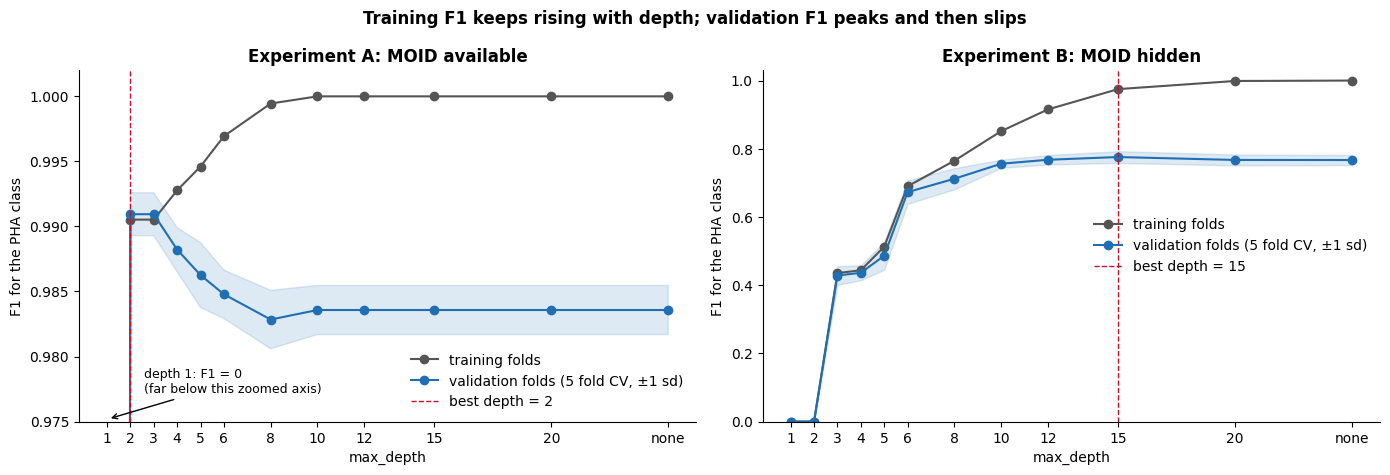

In [11]:
def depth_x(label):
    return 25 if label == "none" else label


fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, exp, title in [(axes[0], "A", "A: MOID available"), (axes[1], "B", "B: MOID hidden")]:
    s = sweep[exp]
    x = s["max_depth"].map(depth_x).astype(float)
    ax.plot(x, s["train_f1"], "o-", color="#555555", label="training folds")
    ax.fill_between(x, s["cv_f1"] - s["cv_f1_std"], s["cv_f1"] + s["cv_f1_std"], color=POS_COLOR, alpha=0.15)
    ax.plot(x, s["cv_f1"], "o-", color=POS_COLOR, label="validation folds (5 fold CV, ±1 sd)")
    best = depth_x(depth_label(BEST_DEPTH[exp]))
    ax.axvline(best, color=PHA_COLOR, ls="--", lw=1, label=f"best depth = {depth_label(BEST_DEPTH[exp])}")
    ax.set_xticks([1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25])
    ax.set_xticklabels(["1", "2", "3", "4", "5", "6", "8", "10", "12", "15", "20", "none"])
    ax.set_xlabel("max_depth")
    ax.set_ylabel("F1 for the PHA class")
    ax.set_title(f"Experiment {title}")
    if exp == "A":
        ax.set_ylim(0.975, 1.002)   # zoomed in, so the small overfitting gap is visible
        ax.annotate("depth 1: F1 = 0\n(far below this zoomed axis)", xy=(1.05, 0.9752), xytext=(2.6, 0.9772),
                    fontsize=9, arrowprops=dict(arrowstyle="->"))
        ax.legend(loc="lower right", frameon=False)
    else:
        ax.set_ylim(0, 1.03)
        ax.legend(loc="center right", frameon=False)
fig.suptitle("Training F1 keeps rising with depth; validation F1 peaks and then slips", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig03_depth_sweep")
plt.show()

In Experiment A the depth 1 tree predicts no PHAs at all (F1 = 0), because one split can't represent an AND of two conditions. Depth 2 is the best (validation F1 0.991). Deeper trees get training F1 up to 1.000, but validation F1 drops to 0.984, so the extra splits are just fitting the 49 noisy labels.

In Experiment B the best depth is 15 (validation F1 0.776, training F1 0.975). ROC AUC peaks earlier, at depth 6 (0.974), and goes down to 0.875 with no depth limit, since very deep leaves only give probabilities of 0 or 1.

### 4.2 Experiment A trees

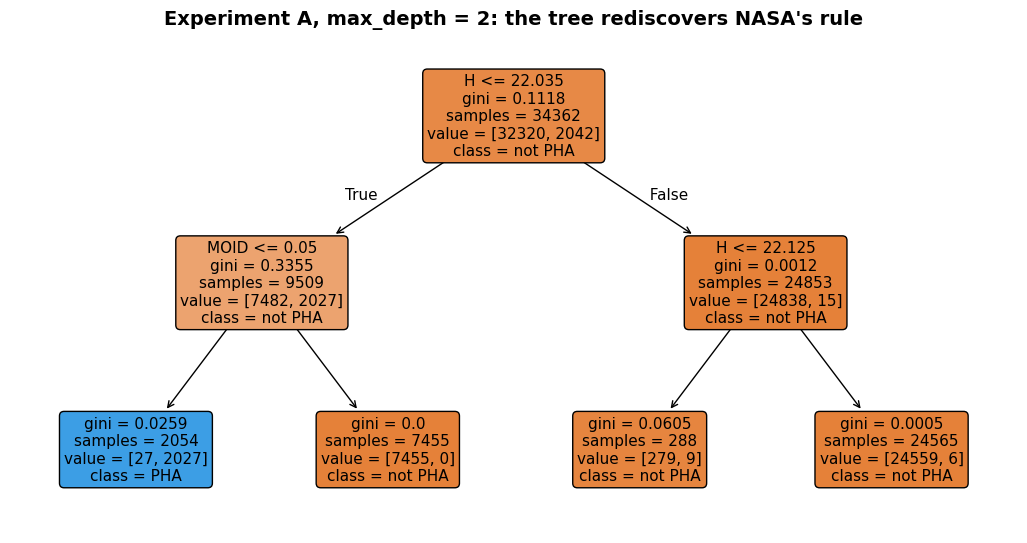

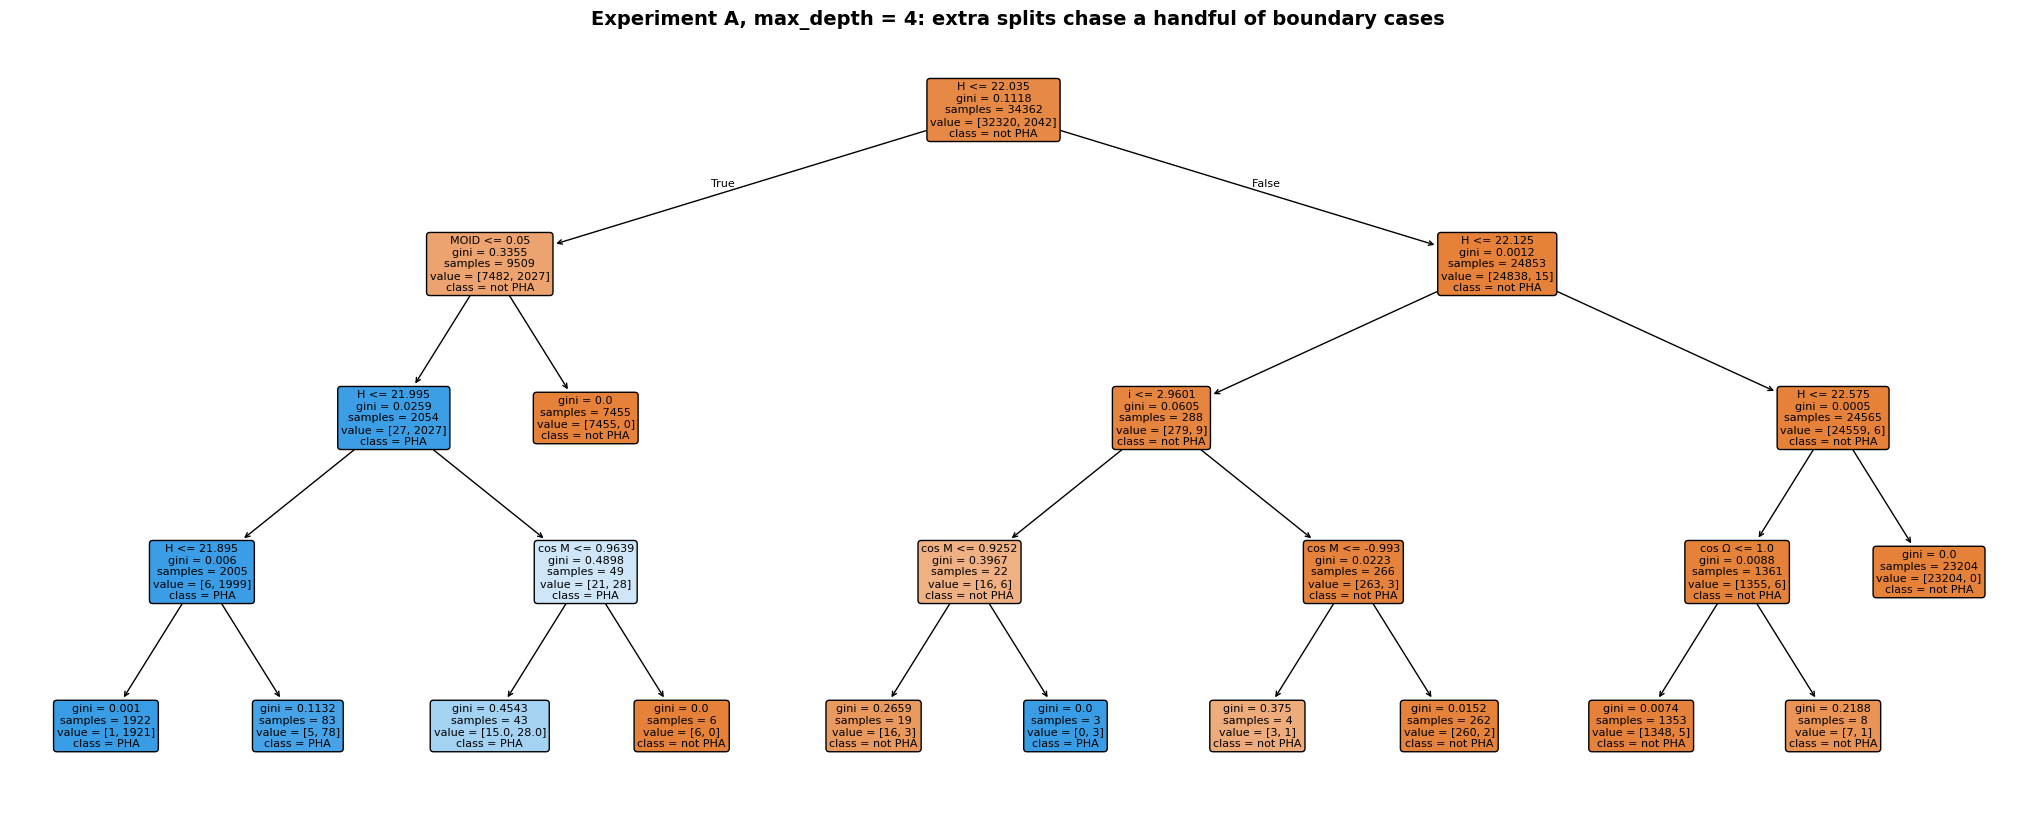

|--- H <= 22.0350
|   |--- MOID <= 0.0500
|   |   |--- class: 1
|   |--- MOID >  0.0500
|   |   |--- class: 0
|--- H >  22.0350
|   |--- H <= 22.1250
|   |   |--- class: 0
|   |--- H >  22.1250
|   |   |--- class: 0



In [12]:
tree_A2 = fit_tree("A", 2)
tree_A4 = fit_tree("A", 4)
show_tree(tree_A2, "A", "Experiment A, max_depth = 2: the tree rediscovers NASA's rule", "fig04_tree_A_depth2", (13, 6.5), 11)
show_tree(tree_A4, "A", "Experiment A, max_depth = 4: extra splits chase a handful of boundary cases", "fig05_tree_A_depth4", (26, 10), 8)
print(export_text(tree_A2, feature_names=[NICE[c] for c in FEATURES["A"]], decimals=4))

In [13]:
def learned_rule(tree, exp):
    """Thresholds the tree uses on the path to its PHA leaf."""
    t, names = tree.tree_, FEATURES[exp]
    leaf_pha = [n for n in range(t.node_count)
                if t.children_left[n] == t.children_right[n] and np.argmax(t.value[n][0]) == 1]
    paths = []
    for leaf in leaf_pha:
        node, steps = leaf, []
        parents = {c: (p, "<=") for p, c in enumerate(t.children_left) if c != -1}
        parents.update({c: (p, ">") for p, c in enumerate(t.children_right) if c != -1})
        while node in parents:
            parent, side = parents[node]
            steps.append((NICE[names[t.feature[parent]]], side, float(t.threshold[parent])))
            node = parent
        paths.append(steps[::-1])
    return paths


rule_paths = learned_rule(tree_A2, "A")
for path in rule_paths:
    print("PHA leaf reached when: " + " AND ".join(f"{f} {s} {v:.4f}" for f, s, v in path))
tree_H = [v for path in rule_paths for f, s, v in path if f == "H" and s == "<="][0]
tree_M = [v for path in rule_paths for f, s, v in path if f == "MOID" and s == "<="][0]
RESULTS["tree_A2"] = {"H_threshold": tree_H, "moid_threshold": tree_M, **score_all(y_test, tree_A2.predict_proba(X("A", idx_test))[:, 1])}
print(f"Official rule:  H <= 22.0000 and MOID <= 0.0500 au")
print(f"Learned rule:   H <= {tree_H:.4f} and MOID <= {tree_M:.4f} au")
print(f"Test F1 of the depth 2 tree: {RESULTS['tree_A2']['f1']:.4f}, accuracy {RESULTS['tree_A2']['accuracy']:.4%}")

PHA leaf reached when: H <= 22.0350 AND MOID <= 0.0500
Official rule:  H <= 22.0000 and MOID <= 0.0500 au
Learned rule:   H <= 22.0350 and MOID <= 0.0500 au
Test F1 of the depth 2 tree: 0.9892, accuracy 99.8720%


The depth 2 tree splits on H ≤ 22.035 first and then MOID ≤ 0.0500 au, which is basically NASA's rule. The H threshold is 22.035 instead of 22.0 because sklearn puts thresholds halfway between data values (22.03 and 22.04 here) and a few flagged asteroids have H between 22.01 and 22.03. The PHA leaf has 2,054 training asteroids and 98.7% of them are PHAs.

The right branch also splits (H ≤ 22.125) even though both leaves predict "not PHA". That split still lowers Gini, because it puts 9 of the 15 flagged small asteroids in one leaf. The depth 4 tree adds splits on i and cos M, which have nothing to do with the rule, so that is overfitting.

### 4.3 Experiment B trees

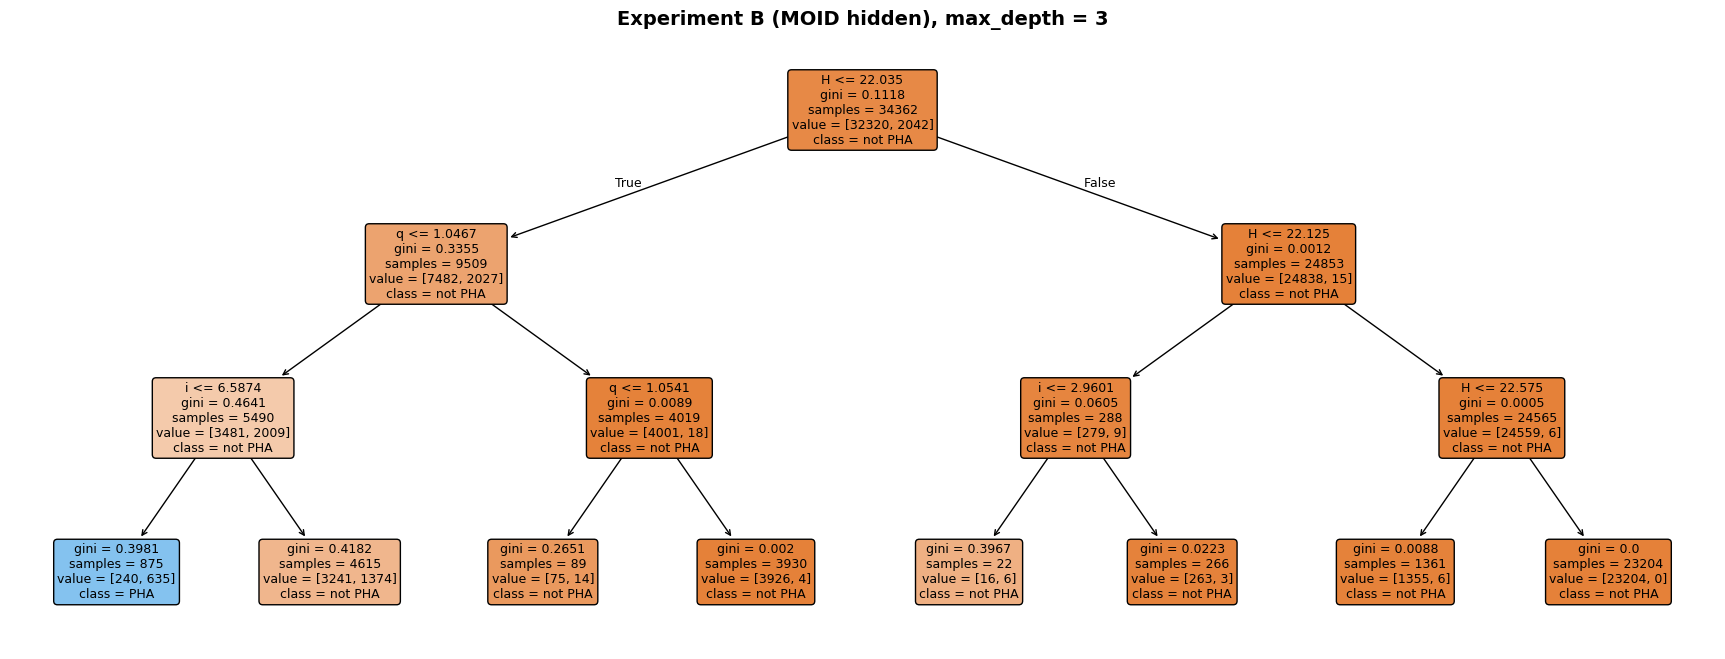

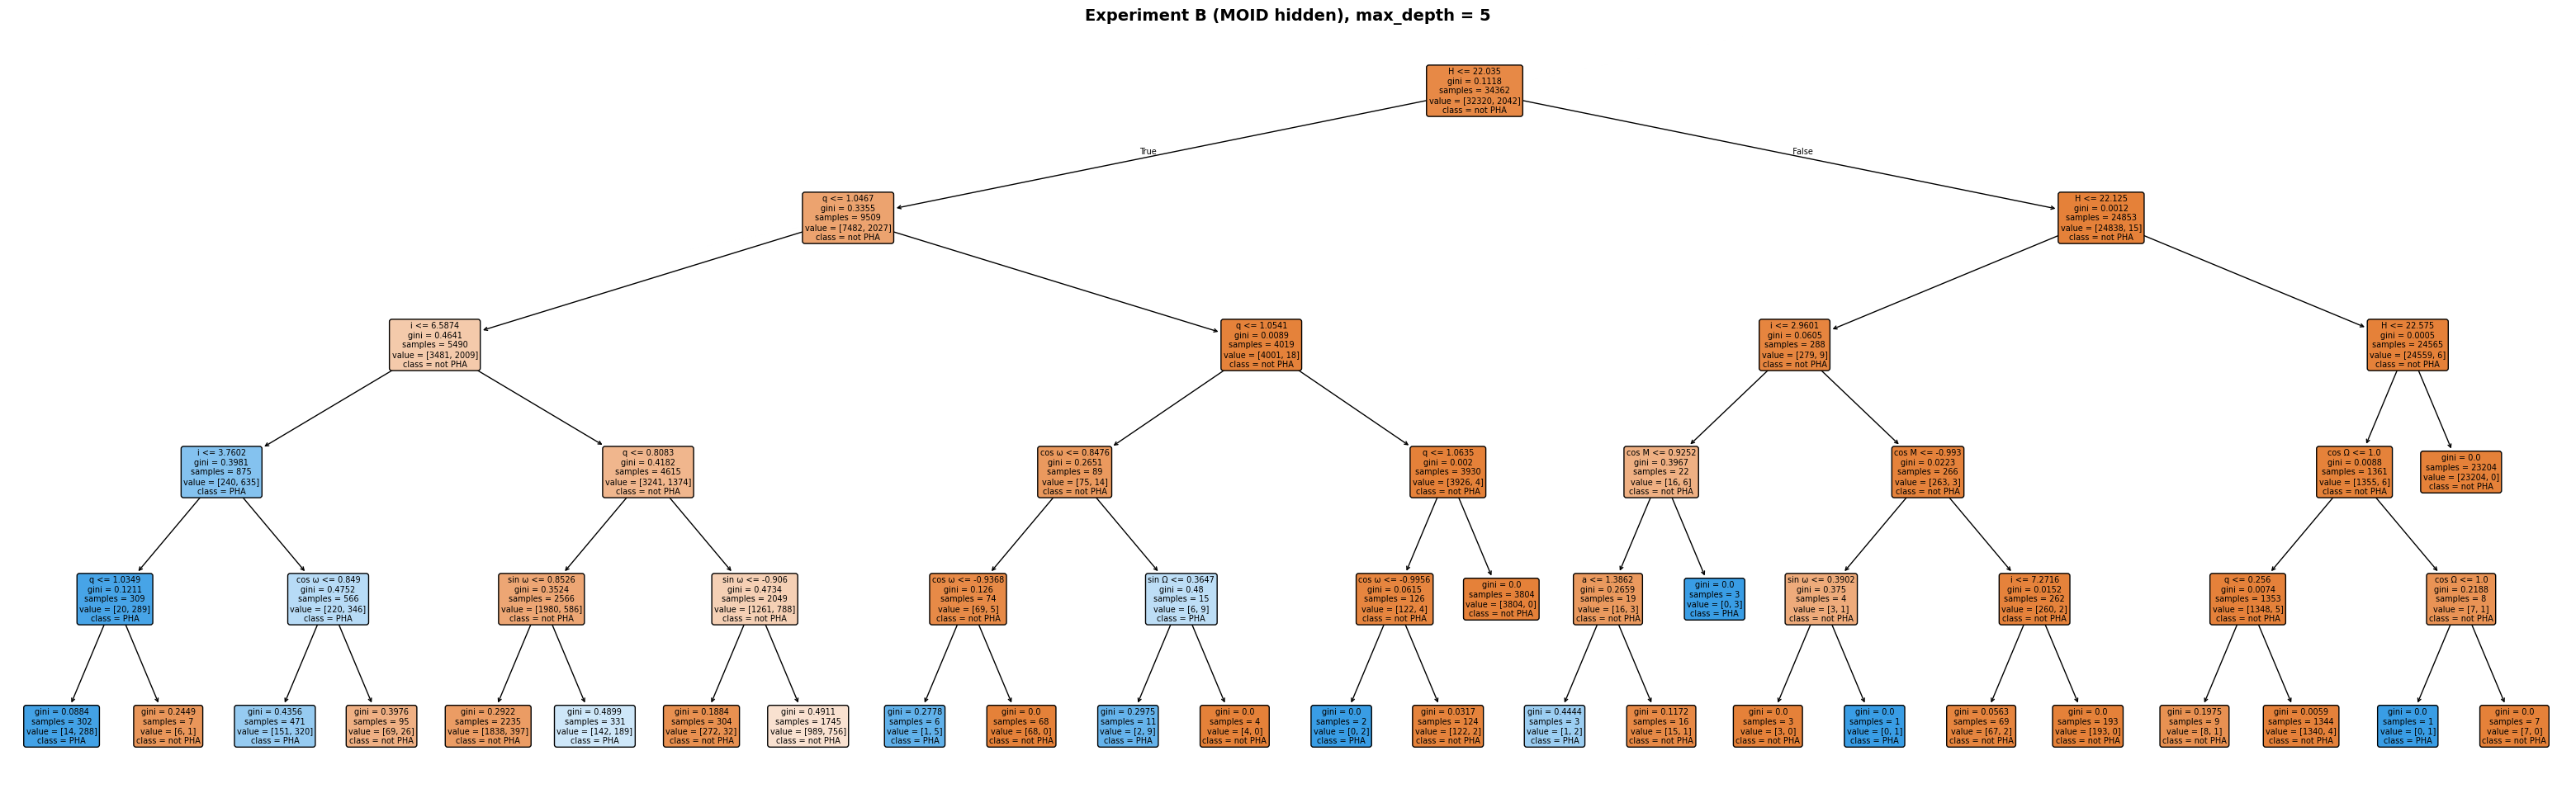

Experiment B tree depth 3: 8 leaves, test F1 0.4568, accuracy 0.9546
Experiment B tree depth 5: 27 leaves, test F1 0.5388, accuracy 0.9572


In [14]:
tree_B3 = fit_tree("B", 3)
tree_B5 = fit_tree("B", 5)
show_tree(tree_B3, "B", "Experiment B (MOID hidden), max_depth = 3", "fig06_tree_B_depth3", (22, 8), 9)
show_tree(tree_B5, "B", "Experiment B (MOID hidden), max_depth = 5", "fig07_tree_B_depth5", (40, 12), 7)
for name, tree in [("depth 3", tree_B3), ("depth 5", tree_B5)]:
    s = score_all(y_test, tree.predict_proba(X("B", idx_test))[:, 1])
    print(f"Experiment B tree {name}: {tree.get_n_leaves()} leaves, test F1 {s['f1']:.4f}, accuracy {s['accuracy']:.4f}")

Without MOID the root is still H ≤ 22.035. Next the tree splits on q ≤ 1.047 au: only 18 of the 4,019 large asteroids with a larger q are PHAs. After that it uses inclination. Large asteroids with q ≤ 1.047 au and i ≤ 6.6° are PHAs 73% of the time, compared to 30% for more tilted orbits, since a flat orbit stays close to Earth's orbital plane. Deeper splits use sin ω and cos ω. The depth 3 tree only gets test F1 0.457 and depth 5 gets 0.539, because approximating a curved boundary with straight cuts takes a lot of splits.

### 4.4 Bias and variance

In [15]:
bv = {exp: bias_variance(exp) for exp in ["A", "B"]}
RESULTS["bias_variance"] = {exp: b.to_dict(orient="records") for exp, b in bv.items()}
for exp in ["A", "B"]:
    print(f"Experiment {exp} (errors per 1,000 test asteroids)")
    shown = bv[exp].copy()
    for c in shown.columns[1:]:
        shown[c] = shown[c] * 1000
    display(shown.style.format(precision=2).hide(axis="index"))

Experiment A (errors per 1,000 test asteroids)


max_depth,expected_error,bias,variance,variance_unbiased,variance_biased,net_variance
1,59.36,59.36,0.00,0.00,0.00,0.00
2,1.38,1.40,0.18,0.08,0.10,-0.02
3,1.46,1.40,0.20,0.13,0.07,0.06
4,1.69,1.40,0.66,0.48,0.18,0.30
5,1.83,1.51,0.80,0.56,0.24,0.32
6,2.07,1.51,1.06,0.80,0.25,0.55
8,2.35,1.51,1.37,1.11,0.27,0.84
10,2.41,1.51,1.41,1.15,0.26,0.90
12,2.43,1.51,1.42,1.17,0.26,0.91
15,2.43,1.51,1.42,1.17,0.26,0.91


Experiment B (errors per 1,000 test asteroids)


max_depth,expected_error,bias,variance,variance_unbiased,variance_biased,net_variance
1,59.36,59.36,0.00,0.00,0.00,0.00
2,59.36,59.36,0.00,0.00,0.00,0.00
3,45.97,45.40,2.37,1.47,0.89,0.58
4,46.31,45.51,3.09,1.95,1.15,0.80
5,44.80,41.67,15.15,9.14,6.01,3.13
6,42.52,37.02,26.90,16.20,10.70,5.50
8,37.35,31.54,22.30,14.05,8.25,5.81
10,33.03,24.91,22.96,15.54,7.42,8.12
12,31.07,21.77,22.98,16.14,6.84,9.30
15,30.09,19.09,23.40,17.20,6.20,11.00


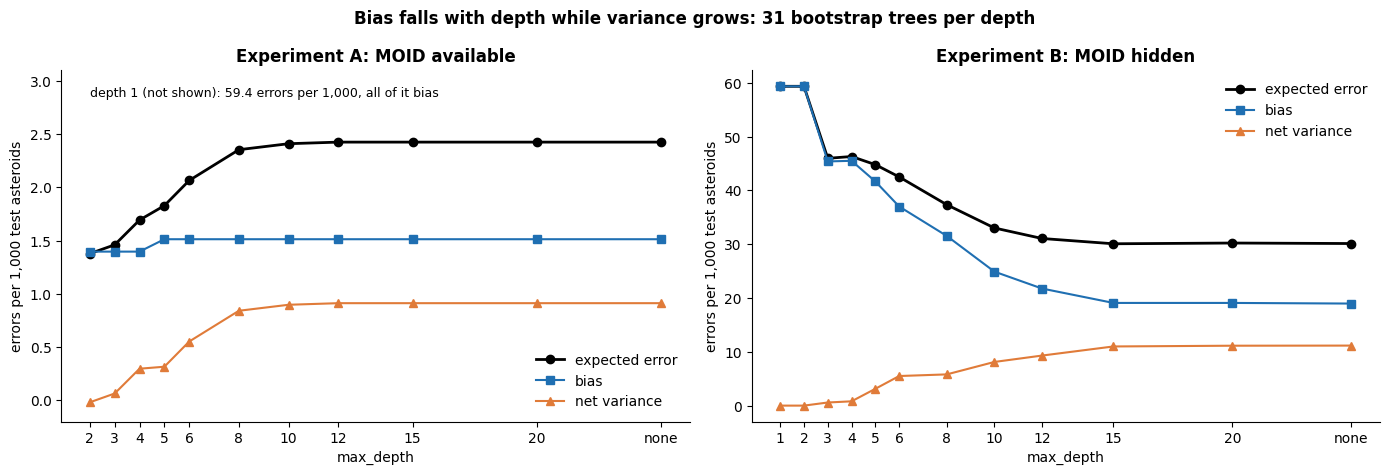

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, exp, title in [(axes[0], "A", "A: MOID available"), (axes[1], "B", "B: MOID hidden")]:
    b = bv[exp]
    if exp == "A":
        depth1_error = 1000 * b["expected_error"].iloc[0]
        b = b[b["max_depth"] != 1]       # depth 1 is 40 times larger; shown as a note instead
    x = b["max_depth"].map(depth_x).astype(float)
    ax.plot(x, 1000 * b["expected_error"], "o-", color="black", lw=2, label="expected error")
    ax.plot(x, 1000 * b["bias"], "s-", color=POS_COLOR, label="bias")
    ax.plot(x, 1000 * b["net_variance"], "^-", color=NEG_COLOR, label="net variance")
    ticks = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25] if exp == "B" else [2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25]
    ax.set_xticks(ticks)
    ax.set_xticklabels([("none" if t == 25 else str(t)) for t in ticks])
    ax.set_xlabel("max_depth")
    ax.set_ylabel("errors per 1,000 test asteroids")
    ax.set_title(f"Experiment {title}")
    if exp == "A":
        ax.set_ylim(-0.2, 3.1)
        ax.text(2, 2.95, f"depth 1 (not shown): {depth1_error:.1f} errors per 1,000, all of it bias",
                fontsize=9, va="top")
        ax.legend(frameon=False, loc="lower right")
    else:
        ax.legend(frameon=False, loc="upper right")
fig.suptitle("Bias falls with depth while variance grows: 31 bootstrap trees per depth", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig08_bias_variance")
plt.show()

In Experiment A, depth 1 makes 59.4 errors per 1,000 test asteroids and all of it is bias. From depth 2 on the bias stays around 1.4 to 1.5, while the net variance goes from about 0 to 0.91, so the error goes up from 1.38 to 2.43. The deeper trees aren't wrong on average, they just change a lot depending on the bootstrap sample.

In Experiment B the bias drops from 59.4 to 19.1 between depth 2 and depth 15, and the net variance goes up to 11.0. The error is lowest at depth 15 (30.1) and stays about the same after that. This matches the depth picked by cross validation.

### 4.5 Do all nodes at a level split on the same attribute?

In [17]:
print("Root candidates in Experiment A: best split per input on all training asteroids")
root_A = best_gain_per_feature(X("A", idx_train), y_train)
display(root_A.head(6).style.format({"best threshold": "{:.4f}", "Gini decrease": "{:.5f}"}).hide(axis="index"))

root_thr = tree_A2.tree_.threshold[0]
root_col = FEATURES["A"][tree_A2.tree_.feature[0]]
left_rows = idx_train[data.loc[idx_train, root_col].values <= root_thr]
right_rows = idx_train[data.loc[idx_train, root_col].values > root_thr]
for side, rows in [("LEFT child (" + NICE[root_col] + f" <= {root_thr:.3f})", left_rows),
                   ("RIGHT child (" + NICE[root_col] + f" > {root_thr:.3f})", right_rows)]:
    sub_y = data.loc[rows, "y"].values
    print(f"\n{side}: {len(rows):,} asteroids, {sub_y.sum():,} PHAs ({sub_y.mean():.2%})")
    display(best_gain_per_feature(X("A", rows), sub_y).head(4)
            .style.format({"best threshold": "{:.4f}", "Gini decrease": "{:.5f}"}).hide(axis="index"))
RESULTS["root_gain_A"] = root_A.head(6).to_dict(orient="records")

Root candidates in Experiment A: best split per input on all training asteroids


input,best threshold,Gini decrease
H,22.0350,0.01809
MOID,0.0500,0.00593
e,0.5999,0.00285
q,0.9860,0.00262
cos M,0.7994,0.00086
Q,4.0342,0.00053



LEFT child (H <= 22.035): 9,509 asteroids, 2,027 PHAs (21.32%)


input,best threshold,Gini decrease
MOID,0.0500,0.32985
q,1.0467,0.06376
i,4.1570,0.01403
e,0.5726,0.00764



RIGHT child (H > 22.035): 24,853 asteroids, 15 PHAs (0.06%)


input,best threshold,Gini decrease
H,22.1250,0.00002
q,0.2550,0.00000
cos Ω,1.0000,0.00000
i,2.9251,0.00000


In [18]:
levels = {}
for name, tree, exp in [("A, depth 4", tree_A4, "A"), ("B, depth 5", tree_B5, "B")]:
    table = splits_by_level(tree, exp)
    levels[name] = table
    summary = table.groupby("level").agg(nodes=("node", "size"),
                                         attributes=("split on", lambda s: ", ".join(sorted(set(s)))),
                                         distinct=("split on", "nunique"))
    print(f"Tree {name}: attributes used at each level")
    display(summary)
RESULTS["levels"] = {k: {int(lvl): sorted(set(s)) for lvl, s in v.groupby("level")["split on"]} for k, v in levels.items()}
print("Every split of the Experiment B depth 5 tree, level by level:")
levels["B, depth 5"].style.format({"PHA share": "{:.3f}", "Gini": "{:.4f}"}).hide(axis="index")

Tree A, depth 4: attributes used at each level


,nodes,attributes,distinct
level,,,
0,1,H,1
1,2,"H, MOID",2
2,3,"H, i",2
3,5,"H, cos M, cos Ω",3


Tree B, depth 5: attributes used at each level


,nodes,attributes,distinct
level,,,
0,1,H,1
1,2,"H, q",2
2,4,"H, i, q",3
3,7,"cos M, cos Ω, cos ω, i, q",5
4,12,"a, cos Ω, cos ω, i, q, sin Ω, sin ω",7


Every split of the Experiment B depth 5 tree, level by level:


level,node,split on,threshold,asteroids,PHA share,Gini
0,0,H,22.035000,34362,0.059,0.1118
1,1,q,1.046700,9509,0.213,0.3355
2,2,i,6.587400,5490,0.366,0.4641
3,3,i,3.760200,875,0.726,0.3981
4,4,q,1.034900,309,0.935,0.1211
4,7,cos ω,0.849000,566,0.611,0.4752
3,10,q,0.808300,4615,0.298,0.4182
4,11,sin ω,0.852600,2566,0.228,0.3524
4,14,sin ω,-0.906000,2049,0.385,0.4734
2,17,q,1.054100,4019,0.004,0.0089


No. At the root every input is compared, and splitting on H lowers Gini by 0.0181 while the best MOID split only lowers it by 0.0059. The H split gives purer children (21.3% PHAs on one side and 0.06% on the other, compared to about 11% and 0% for MOID). The order doesn't change the final rule since an AND works either way.

After the root, the two children have different asteroids, and CART picks the best split for each one separately. The left child (9,509 large asteroids, 21.3% PHAs) splits on MOID (Gini decrease 0.330). The right child (24,853 small asteroids with only 15 PHAs) splits on H again to catch the flagged ones just past the cutoff. So the two nodes at level 1 use different attributes.

In the Experiment B tree this gets stronger with depth: the number of different attributes per level goes 1, 2, 3, 5, 7. Each branch is dealing with a different kind of orbit (flat or tilted, perihelion inside or outside Earth's orbit), so the best question is different. A whole level only uses one attribute if that attribute happens to be best for every node, which almost never happens after the root.

### 4.6 Neural networks

In [19]:
runs, nets, nn_summary = {}, {}, {}
for exp in ["A", "B"]:
    runs[exp], nets[exp] = train_networks(exp)
    nn_summary[exp] = summarize(runs[exp])
    print(f"Experiment {exp}: test scores, mean ± sd over {len(SEEDS)} seeds")
    display(pretty(nn_summary[exp]))
RESULTS["nn_runs"] = {exp: r.to_dict(orient="records") for exp, r in runs.items()}
RESULTS["nn_summary"] = {exp: s.reset_index().to_dict(orient="records") for exp, s in nn_summary.items()}

Experiment A: test scores, mean ± sd over 5 seeds


,parameters,epochs,accuracy,balanced_accuracy,f1,roc_auc,avg_precision
architecture,,,,,,,
Tiny (2),31,146,0.9925 ± 0.0108,0.9650 ± 0.0491,0.9364 ± 0.0917,0.9978 ± 0.0042,0.9667 ± 0.0683
Small (8),121,105,0.9976 ± 0.0002,0.9875 ± 0.0022,0.9793 ± 0.0017,0.9999 ± 0.0000,0.9980 ± 0.0001
"Medium (16, 8)",369,99,0.9968 ± 0.0003,0.9864 ± 0.0026,0.9734 ± 0.0026,0.9998 ± 0.0000,0.9974 ± 0.0004
"Deep (32, 16, 8)",1121,92,0.9956 ± 0.0004,0.9787 ± 0.0032,0.9626 ± 0.0030,0.9997 ± 0.0001,0.9955 ± 0.0008


Experiment B: test scores, mean ± sd over 5 seeds


,parameters,epochs,accuracy,balanced_accuracy,f1,roc_auc,avg_precision
architecture,,,,,,,
Tiny (2),29,85,0.9419 ± 0.0028,0.5211 ± 0.0471,0.0655 ± 0.1464,0.9458 ± 0.0085,0.4047 ± 0.0413
Small (8),113,200,0.9652 ± 0.0051,0.7848 ± 0.0411,0.6621 ± 0.0636,0.9840 ± 0.0055,0.7857 ± 0.0656
"Medium (16, 8)",353,221,0.9823 ± 0.0031,0.9077 ± 0.0213,0.8460 ± 0.0290,0.9954 ± 0.0010,0.9331 ± 0.0169
"Deep (32, 16, 8)",1089,203,0.9840 ± 0.0030,0.9272 ± 0.0129,0.8650 ± 0.0249,0.9961 ± 0.0010,0.9423 ± 0.0149


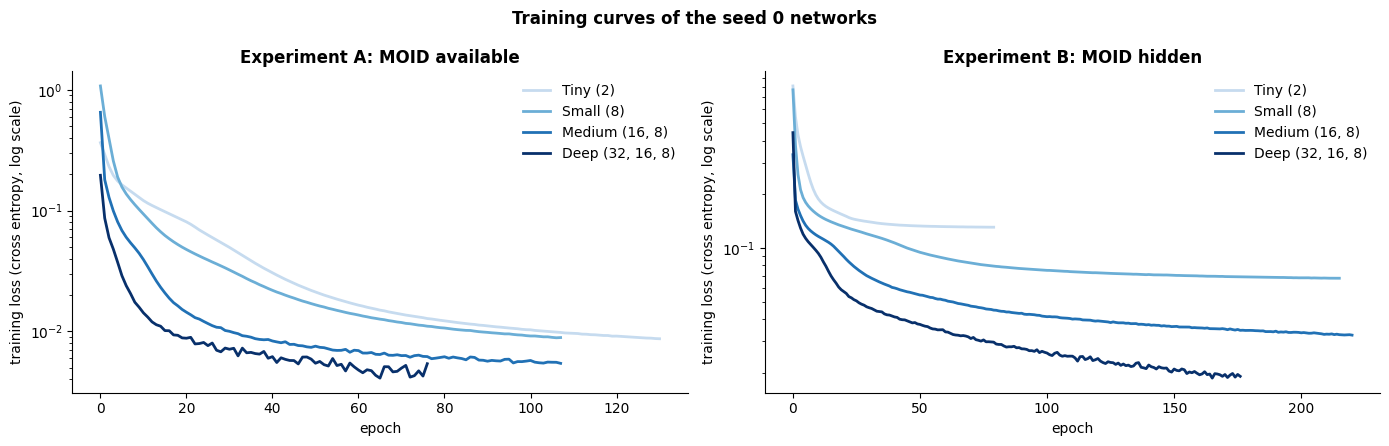

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
shades = ["#c6dbef", "#6baed6", "#2171b5", "#08306b"]
for ax, exp, title in [(axes[0], "A", "A: MOID available"), (axes[1], "B", "B: MOID hidden")]:
    for (name, net), color in zip(nets[exp].items(), shades):
        ax.plot(net[-1].loss_curve_, color=color, lw=2, label=name)
    ax.set_yscale("log")
    ax.set_xlabel("epoch")
    ax.set_ylabel("training loss (cross entropy, log scale)")
    ax.set_title(f"Experiment {title}")
    ax.legend(frameon=False)
fig.suptitle("Training curves of the seed 0 networks", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig09_loss_curves")
plt.show()

With MOID available, Small, Medium and Deep get F1 between 0.963 and 0.979, a bit below the depth 2 tree (0.989). Their ROC AUC is higher though (0.9997 to 0.9999 vs 0.9966 for the tree), so they rank asteroids well but the smooth boundary blurs the corner of the rule a little. Bigger was not better here: Deep had the lowest F1 of the three. Tiny worked for four seeds (F1 0.976 to 0.979), but seed 4 got stuck at 0.772, which is why its standard deviation is large.

With MOID hidden the network size matters a lot. Tiny basically fails (four of five seeds never predict a PHA, F1 0.066), Small gets 0.662, Medium 0.846 and Deep 0.865. The difference between Medium and Deep is smaller than one standard deviation. In B the bigger networks also train longer, about 200 epochs on average compared to 100 to 150 in A.

### 4.7 Network diagrams

Each diagram shows every node and edge of the seed 0 network. Blue is a positive weight and orange is negative. Thicker and darker edges are bigger weights (scaled within each layer).

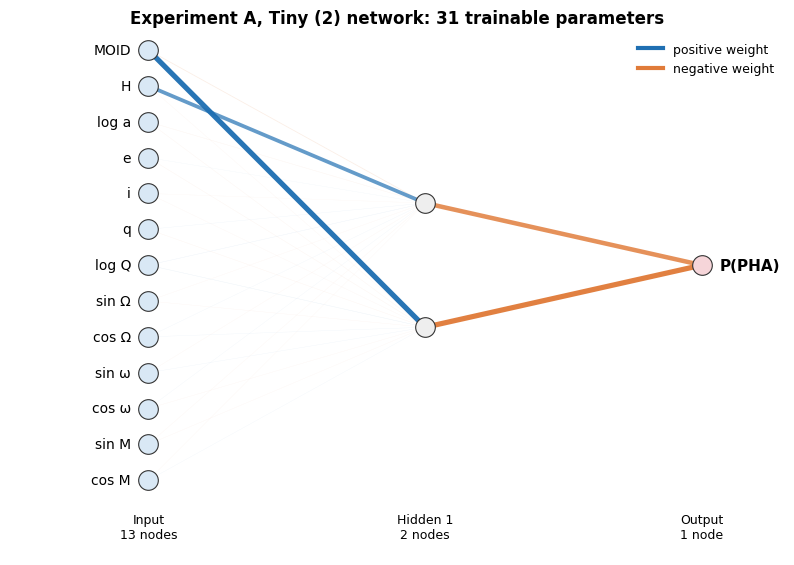

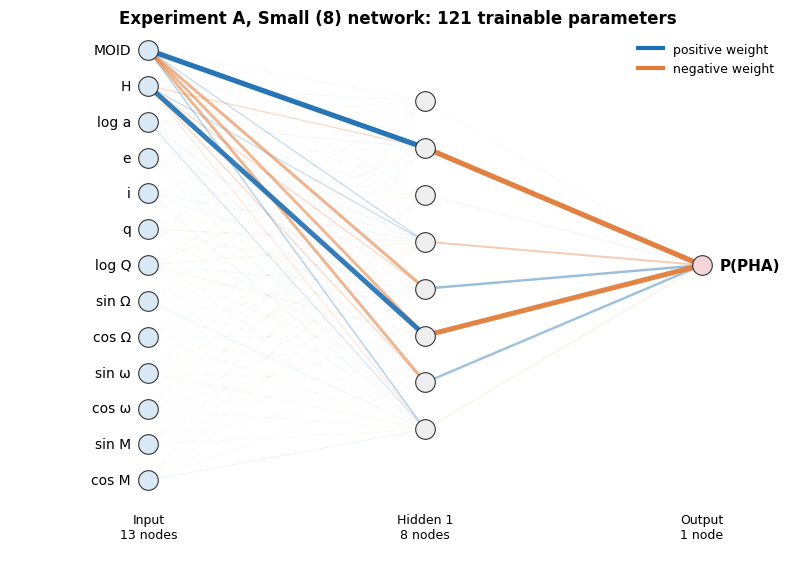

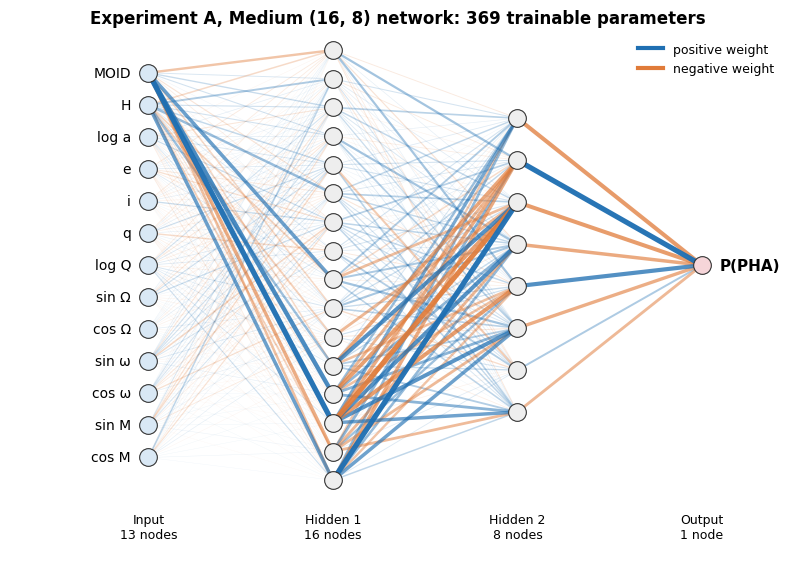

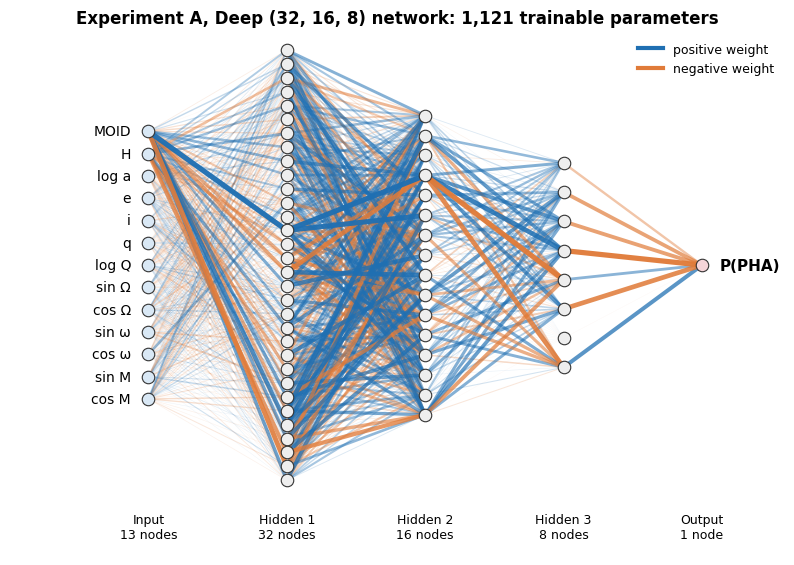

In [21]:
slug = {"Tiny (2)": "tiny", "Small (8)": "small", "Medium (16, 8)": "medium", "Deep (32, 16, 8)": "deep"}
for name, net in nets["A"].items():
    draw_network(net, "A", f"Experiment A, {name} network", f"fig10_net_A_{slug[name]}")

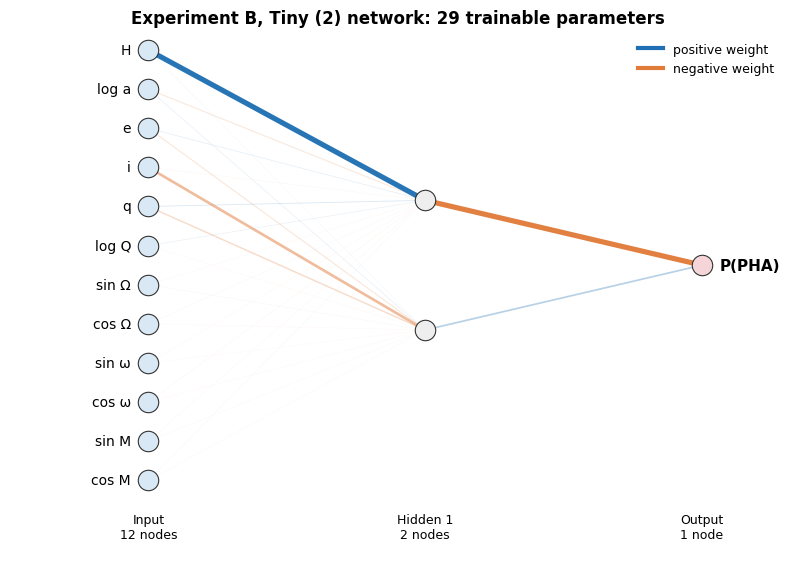

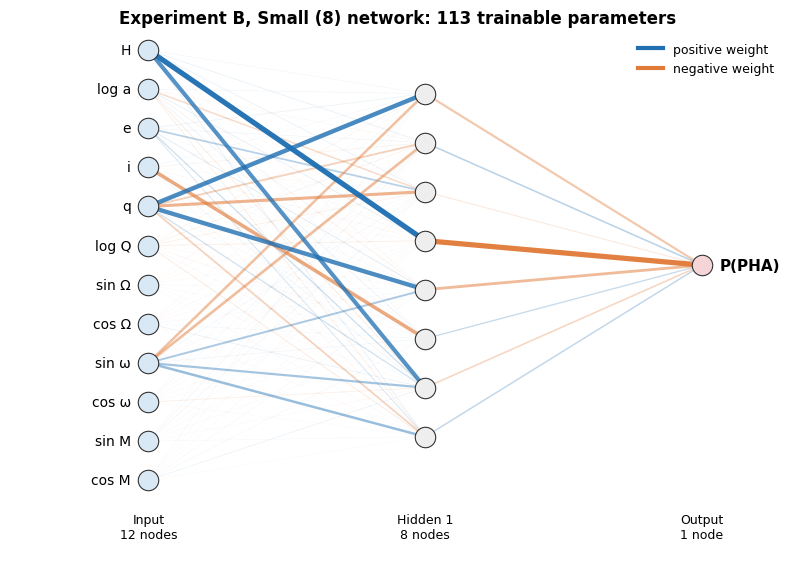

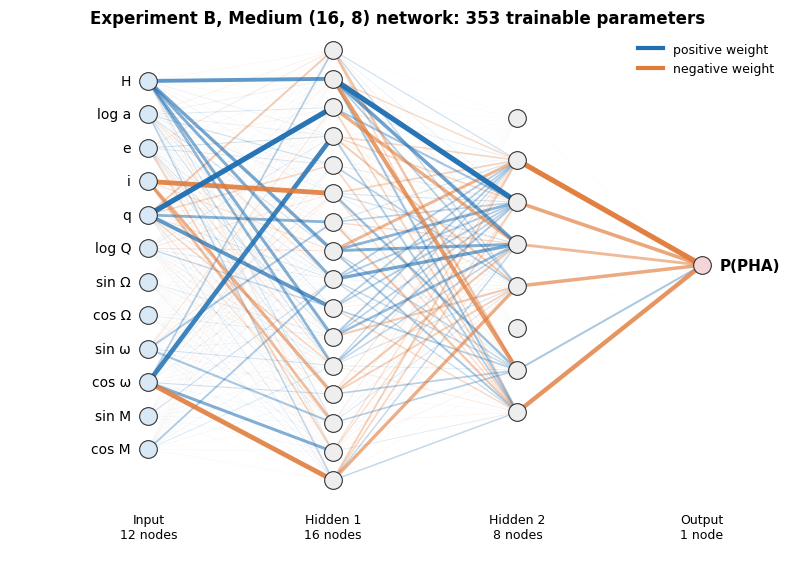

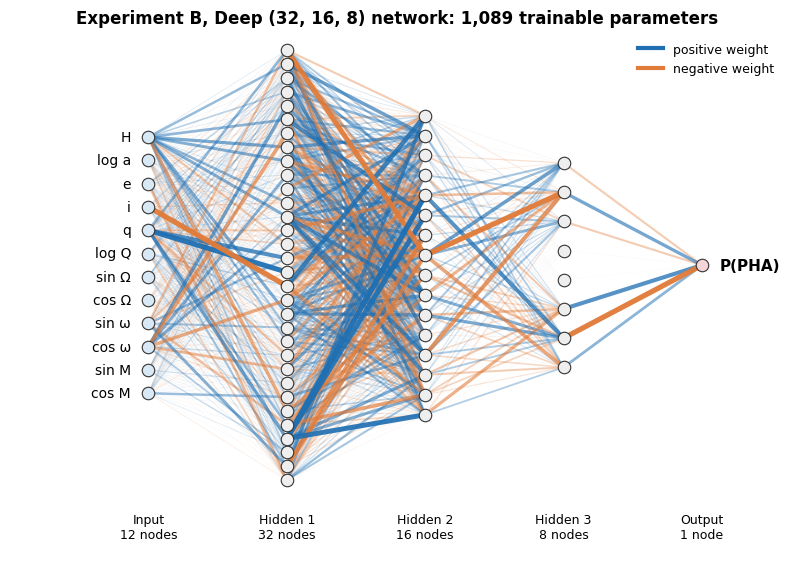

In [22]:
for name, net in nets["B"].items():
    draw_network(net, "B", f"Experiment B, {name} network", f"fig11_net_B_{slug[name]}")

In the Tiny network two edges stand out: MOID goes to one hidden neuron and H to the other, and both neurons connect to the output with large negative weights. The other inputs are almost invisible. In the bigger networks the weights are much more spread out, and the Deep network has visible edges from every input, even inputs it barely uses (see 4.8). With MOID hidden, the biggest first layer weights in the Medium network come from q, cos ω, H and i, which are also the features the tree splits on.

### 4.8 Edge weights vs tree splits

In [23]:
best_tree = {exp: fit_tree(exp, BEST_DEPTH[exp]) for exp in ["A", "B"]}
imp, rho_rows = {}, []
for exp in ["A", "B"]:
    t = pd.DataFrame(index=[NICE[c] for c in FEATURES[exp]])
    t["Tree: Gini"] = best_tree[exp].feature_importances_
    t["Tree: permutation"] = perm_importance(best_tree[exp], exp)
    for name, net in nets[exp].items():
        t[f"{name}: first layer |w|"] = first_layer_importance(net)
        t[f"{name}: Olden"] = olden_importance(net)[1]
        t[f"{name}: permutation"] = perm_importance(net, exp)
        rho_rows.append({"experiment": exp, "network": name,
                         "first layer |w| vs tree Gini": spearmanr(t[f"{name}: first layer |w|"], t["Tree: Gini"]).correlation,
                         "Olden vs tree Gini": spearmanr(t[f"{name}: Olden"], t["Tree: Gini"]).correlation,
                         "network vs tree permutation": spearmanr(t[f"{name}: permutation"], t["Tree: permutation"]).correlation})
    imp[exp] = t
rho = pd.DataFrame(rho_rows)
RESULTS["importance"] = {exp: t.round(5).to_dict() for exp, t in imp.items()}
RESULTS["spearman"] = rho.to_dict(orient="records")
print("Spearman rank correlation between network and tree importances (13 or 12 inputs)")
display(rho.style.format(precision=3).hide(axis="index"))

Spearman rank correlation between network and tree importances (13 or 12 inputs)


experiment,network,first layer |w| vs tree Gini,Olden vs tree Gini,network vs tree permutation
A,Tiny (2),0.629,0.629,0.629
A,Small (8),0.629,0.629,0.630
A,"Medium (16, 8)",0.629,0.629,0.629
A,"Deep (32, 16, 8)",0.629,0.629,0.647
B,Tiny (2),0.413,0.517,0.581
B,Small (8),0.720,0.580,0.809
B,"Medium (16, 8)",0.769,0.483,0.834
B,"Deep (32, 16, 8)",0.734,0.643,0.879


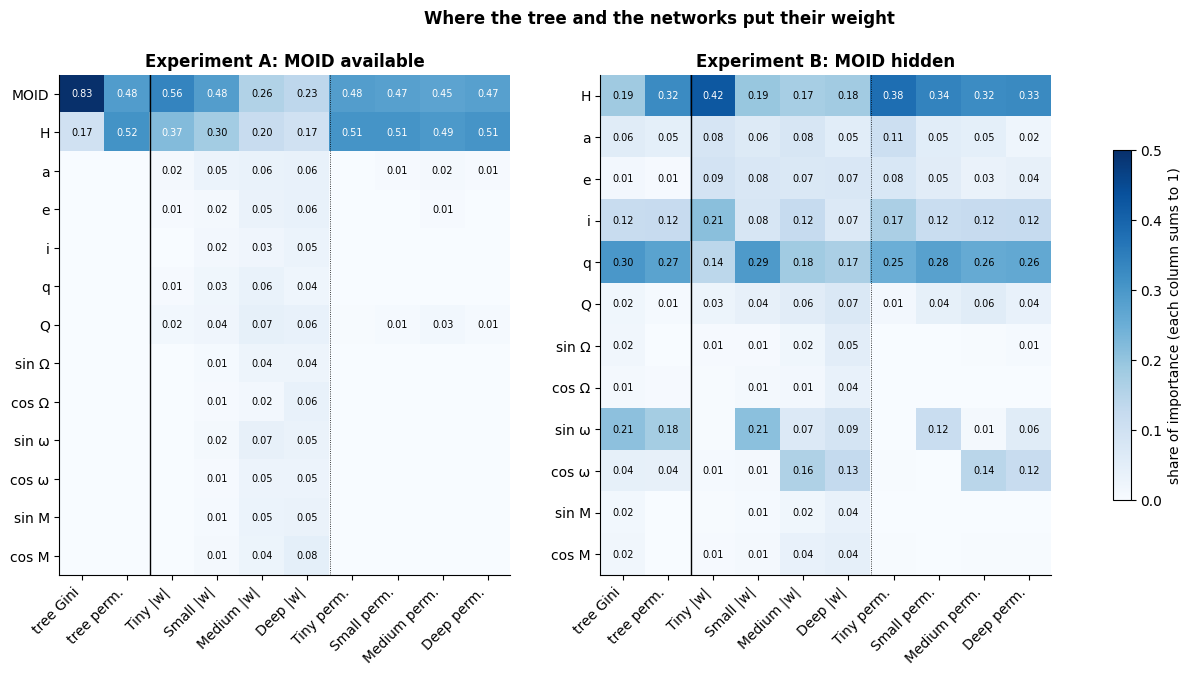

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1]})
for ax, exp, title in [(axes[0], "A", "A: MOID available"), (axes[1], "B", "B: MOID hidden")]:
    cols = ["Tree: Gini", "Tree: permutation"] + [f"{n}: first layer |w|" for n in ARCHS] + [f"{n}: permutation" for n in ARCHS]
    m = imp[exp][cols]
    im = ax.imshow(m.values, cmap="Blues", vmin=0, vmax=max(0.5, m.values.max()), aspect="auto")
    ax.set_yticks(range(len(m.index)))
    ax.set_yticklabels(m.index)
    short = ["tree Gini", "tree perm."] + [f"{n.split(' ')[0]} |w|" for n in ARCHS] + [f"{n.split(' ')[0]} perm." for n in ARCHS]
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(short, rotation=45, ha="right")
    for r in range(m.shape[0]):
        for c in range(m.shape[1]):
            v = m.values[r, c]
            ax.text(c, r, f"{v:.2f}" if v >= 0.005 else "", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.3 else "black")
    ax.axvline(1.5, color="black", lw=1)
    ax.axvline(5.5, color="black", lw=0.6, ls=":")
    ax.set_title(f"Experiment {title}")
fig.colorbar(im, ax=axes, shrink=0.7, label="share of importance (each column sums to 1)")
fig.suptitle("Where the tree and the networks put their weight", fontweight="bold")
savefig(fig, "fig12_importance_heatmap")
plt.show()

In Experiment A all networks and the tree rank MOID and H as the two most important inputs. Spearman ρ is 0.629 for every comparison, but that is the maximum possible here because the tree gives the other 11 inputs zero importance (lots of ties). Permutation importance is the easiest to compare: the tree uses MOID 48% and H 52%, and the networks are close (45 to 48% MOID, 49 to 52% H).

The first layer weights don't agree as well. The share of first layer weight on MOID and H drops from 93% (Tiny) to 78% (Small), 46% (Medium) and 39% (Deep), even though permutation importance for every network is still at least 94.6% on those two inputs. Our explanation is that weights from inputs the network doesn't use get almost no gradient, so they stay close to their random starting values, and with 32 first layer neurons that adds up. So in a bigger network a large weight doesn't necessarily mean the input matters. Gini importance has its own bias too: it gives MOID 83%, while permutation importance shows H matters just as much.

With MOID hidden the agreement is weaker but still there: ρ = 0.72 to 0.77 between first layer weights and Gini importance, and ρ = 0.81 to 0.88 between the permutation importances (Small, Medium and Deep). Both model types rely most on H, q and i. One difference is that the tree uses sin ω while the Medium and Deep networks use cos ω. Both describe where the orbit crosses Earth's plane, since the node distances are a(1 − e²)/(1 ± e cos ω).

#### The Tiny network

In [25]:
tiny = nets["A"]["Tiny (2)"]
W1 = pd.DataFrame(tiny[-1].coefs_[0], index=[NICE[c] for c in FEATURES["A"]], columns=["neuron 1", "neuron 2"])
acts = hidden_activations(tiny, X("A", idx_test))[0]
corr = pd.DataFrame({n: [spearmanr(acts[:, j], data.loc[idx_test, v]).correlation for v in ["moid", "H"]]
                     for j, n in enumerate(W1.columns)}, index=["ρ with MOID", "ρ with H"])
out_w = tiny[-1].coefs_[1].ravel()
print("First layer weights of the Tiny network (inputs standardized):")
display(W1.T.style.format(precision=2))
print("Spearman correlation of each neuron's activation with MOID and H (test set):")
display(corr.style.format(precision=3))
print(f"Output weights: {out_w.round(2)}, output bias {tiny[-1].intercepts_[1][0]:.2f}")

First layer weights of the Tiny network (inputs standardized):


,MOID,H,a,e,i,q,Q,sin Ω,cos Ω,sin ω,cos ω,sin M,cos M
neuron 1,-0.50,4.41,-0.14,0.00,-0.00,0.03,0.13,-0.02,0.01,-0.01,0.00,-0.01,-0.00
neuron 2,6.29,-0.02,-0.08,-0.11,-0.01,-0.07,0.15,-0.01,0.01,0.01,-0.01,-0.01,0.00


Spearman correlation of each neuron's activation with MOID and H (test set):


,neuron 1,neuron 2
ρ with MOID,-0.707,0.934
ρ with H,0.988,-0.627


Output weights: [-7.5  -8.76], output bias 4.64


In [26]:
def implied_thresholds(model, exp, H_inside=20.0, moid_inside=0.02):
    """Scan MOID (with H well inside the zone) and H (with MOID inside) to find where P(PHA) crosses 0.5."""
    base = X(exp, idx_train).median()
    grid_m = np.linspace(0.0, 0.2, 4001)
    rows = pd.DataFrame([base.values] * len(grid_m), columns=base.index)
    rows["moid"], rows["H"] = grid_m, H_inside
    pm = model.predict_proba(rows)[:, 1] >= 0.5
    grid_h = np.linspace(14, 28, 2801)
    rows = pd.DataFrame([base.values] * len(grid_h), columns=base.index)
    rows["moid"], rows["H"] = moid_inside, grid_h
    ph = model.predict_proba(rows)[:, 1] >= 0.5
    return (grid_m[pm].max() if pm.any() else np.nan), (grid_h[ph].max() if ph.any() else np.nan)


thr_rows = [{"model": "NASA definition", "MOID threshold (au)": 0.05, "H threshold (mag)": 22.0}]
m_t, h_t = implied_thresholds(tree_A2, "A")
thr_rows.append({"model": "Decision tree, depth 2", "MOID threshold (au)": m_t, "H threshold (mag)": h_t})
for name, net in nets["A"].items():
    m_t, h_t = implied_thresholds(net, "A")
    thr_rows.append({"model": f"Network {name}", "MOID threshold (au)": m_t, "H threshold (mag)": h_t})
thresholds = pd.DataFrame(thr_rows)
RESULTS["implied_thresholds"] = thresholds.to_dict(orient="records")
RESULTS["tiny_net"] = {"W1": W1.round(3).to_dict(), "corr": corr.round(3).to_dict(),
                       "out_w": out_w.round(3).tolist(), "out_b": float(tiny[-1].intercepts_[1][0])}
print("Where each model draws the hazard boundary (other inputs at their median values)")
thresholds.style.format({"MOID threshold (au)": "{:.4f}", "H threshold (mag)": "{:.3f}"}).hide(axis="index")

Where each model draws the hazard boundary (other inputs at their median values)


model,MOID threshold (au),H threshold (mag)
NASA definition,0.0500,22.000
"Decision tree, depth 2",0.0500,22.035
Network Tiny (2),0.0505,22.010
Network Small (8),0.0509,22.035
"Network Medium (16, 8)",0.0511,22.105
"Network Deep (32, 16, 8)",0.0520,22.185


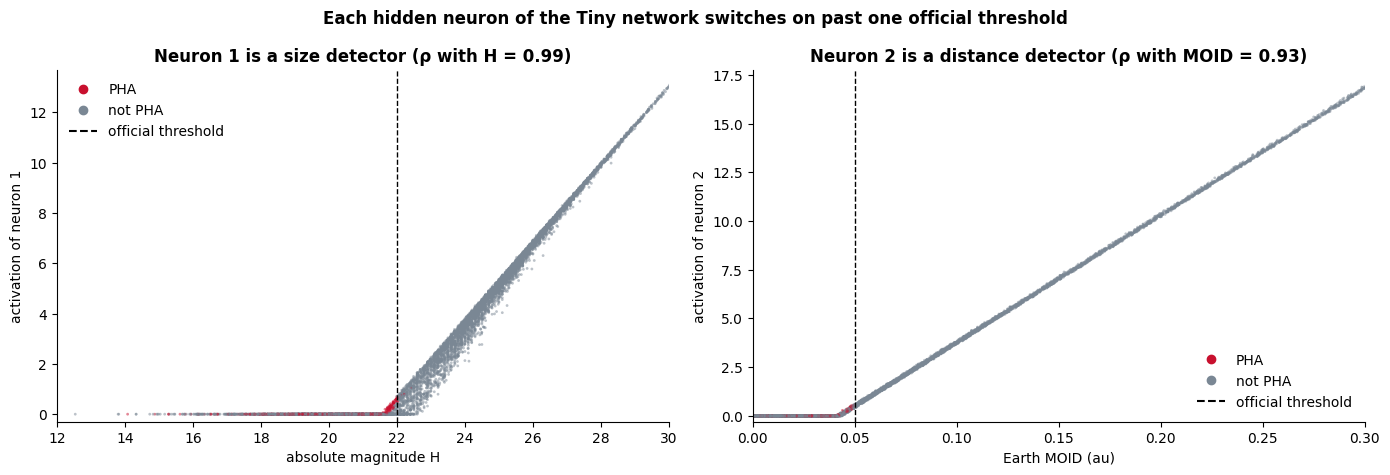

In [27]:
size_n = int(np.argmax(np.abs(corr.loc["ρ with H"].values)))
dist_n = int(np.argmax(np.abs(corr.loc["ρ with MOID"].values)))
test = data.loc[idx_test]
colors = np.where(test["y"] == 1, PHA_COLOR, "#7a8794")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].scatter(test["H"], acts[:, size_n], c=colors, s=4, alpha=0.5, linewidths=0, rasterized=True)
axes[0].axvline(22, color="black", ls="--", lw=1)
axes[0].set_xlim(12, 30)
axes[0].set_xlabel("absolute magnitude H")
axes[0].set_ylabel(f"activation of neuron {size_n + 1}")
axes[0].set_title(f"Neuron {size_n + 1} is a size detector (ρ with H = {corr.iloc[1, size_n]:.2f})")
axes[1].scatter(test["moid"], acts[:, dist_n], c=colors, s=4, alpha=0.5, linewidths=0, rasterized=True)
axes[1].axvline(0.05, color="black", ls="--", lw=1)
axes[1].set_xlim(0, 0.3)
axes[1].set_xlabel("Earth MOID (au)")
axes[1].set_ylabel(f"activation of neuron {dist_n + 1}")
axes[1].set_title(f"Neuron {dist_n + 1} is a distance detector (ρ with MOID = {corr.iloc[0, dist_n]:.2f})")
in_view_H = (test["H"].values >= 12) & (test["H"].values <= 30)
in_view_M = test["moid"].values <= 0.3
axes[0].set_ylim(-0.3, acts[in_view_H, size_n].max() * 1.05)
axes[1].set_ylim(-0.3, acts[in_view_M, dist_n].max() * 1.05)
for ax in axes:
    ax.legend(handles=[Line2D([0], [0], marker="o", ls="", color=PHA_COLOR, label="PHA"),
                       Line2D([0], [0], marker="o", ls="", color="#7a8794", label="not PHA"),
                       Line2D([0], [0], color="black", ls="--", label="official threshold")], frameon=False)
fig.suptitle("Each hidden neuron of the Tiny network switches on past one official threshold", fontweight="bold")
fig.tight_layout()
savefig(fig, "fig13_tiny_neurons")
plt.show()

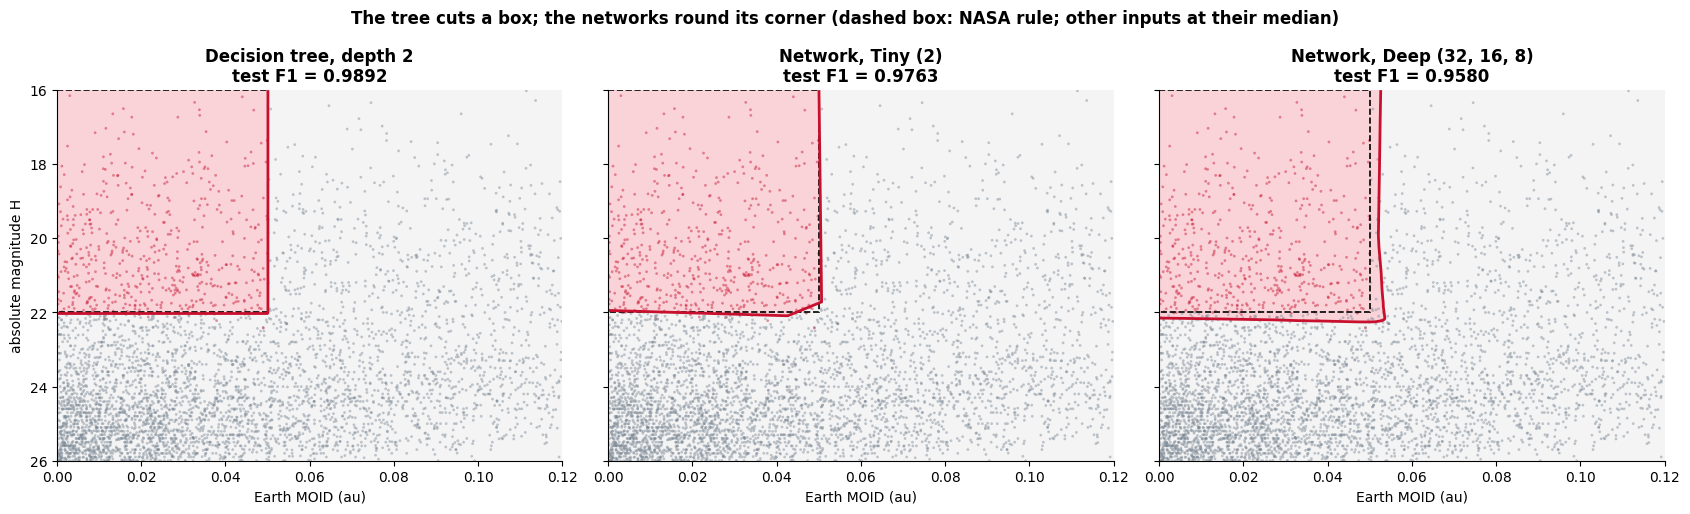

In [28]:
# Decision boundaries of the analyzed Experiment A models in the MOID and H plane.
# Every other input is held at its training median (these models barely use them).
boundary_models = {"Decision tree, depth 2": tree_A2,
                   "Network, Tiny (2)": nets["A"]["Tiny (2)"],
                   "Network, Deep (32, 16, 8)": nets["A"]["Deep (32, 16, 8)"]}
gx, gy = np.meshgrid(np.linspace(0, 0.12, 400), np.linspace(16, 26, 400))
base = X("A", idx_train).median()
grid = pd.DataFrame(np.tile(base.values, (gx.size, 1)), columns=base.index)
grid["moid"], grid["H"] = gx.ravel(), gy.ravel()
sample = data.loc[idx_test]
sample = sample[(sample["moid"] <= 0.12) & sample["H"].between(16, 26)]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharey=True)
RESULTS["boundary_models"] = {}
for ax, (name, model) in zip(axes, boundary_models.items()):
    proba = model.predict_proba(grid)[:, 1].reshape(gx.shape)
    ax.contourf(gx, gy, proba, levels=[0, 0.5, 1], colors=["#f4f4f4", "#f9d3d8"])
    ax.contour(gx, gy, proba, levels=[0.5], colors=[PHA_COLOR], linewidths=2)
    ax.scatter(sample["moid"], sample["H"], c=np.where(sample["y"] == 1, PHA_COLOR, "#7a8794"),
               s=4, alpha=0.45, linewidths=0, rasterized=True)
    ax.add_patch(Rectangle((0, 16), 0.05, 6, fill=False, ec="black", ls="--", lw=1.2))
    f1 = f1_score(y_test, model.predict(X("A", idx_test)))
    RESULTS["boundary_models"][name] = f1
    ax.set_title(f"{name}\ntest F1 = {f1:.4f}")
    ax.set_xlabel("Earth MOID (au)")
axes[0].set_ylabel("absolute magnitude H")
axes[0].invert_yaxis()
fig.suptitle("The tree cuts a box; the networks round its corner (dashed box: NASA rule; other inputs at their median)",
             fontweight="bold")
fig.tight_layout()
savefig(fig, "fig14_decision_boundaries")
plt.show()

Neuron 1 of the Tiny network has a weight of 4.41 on H and its activation correlates with H (ρ = 0.99). Neuron 2 has a weight of 6.29 on MOID (ρ = 0.93). All the other input weights are 0.5 or less. Both neurons are ReLUs that stay at 0 inside the PHA region and turn on past the official thresholds (Figure 13). Both have negative output weights, so if either one turns on the prediction goes to "not PHA". That is the same AND logic as the depth 2 tree.

The boundary of the Tiny network is at H ≤ 22.01 and MOID ≤ 0.0505 au, which is even closer to the official rule than the tree. The bigger networks are further off (Deep: H ≤ 22.19 and MOID ≤ 0.0520 au). In Figure 14 the tree's boundary is a rectangle and the networks have a slightly rounded corner.

### 4.9 Did the networks learn MOID on their own?

In Experiment B the models never see MOID. If a network still learns something like it, MOID should be easier to predict from its hidden layers than from the raw inputs. To test this we fit a ridge regression (a linear "probe") from each layer's activations to log10 MOID on the training set and check R² on the test set.

representation,all asteroids,large asteroids (H ≤ 22)
raw inputs (12),0.551,0.267
"Tiny (2), hidden layer 1 (2)",0.515,0.223
"Small (8), hidden layer 1 (8)",0.630,0.556
"Medium (16, 8), hidden layer 1 (16)",0.648,0.472
"Medium (16, 8), hidden layer 2 (8)",0.617,0.649
"Deep (32, 16, 8), hidden layer 1 (32)",0.657,0.522
"Deep (32, 16, 8), hidden layer 2 (16)",0.643,0.623
"Deep (32, 16, 8), hidden layer 3 (8)",0.533,0.672


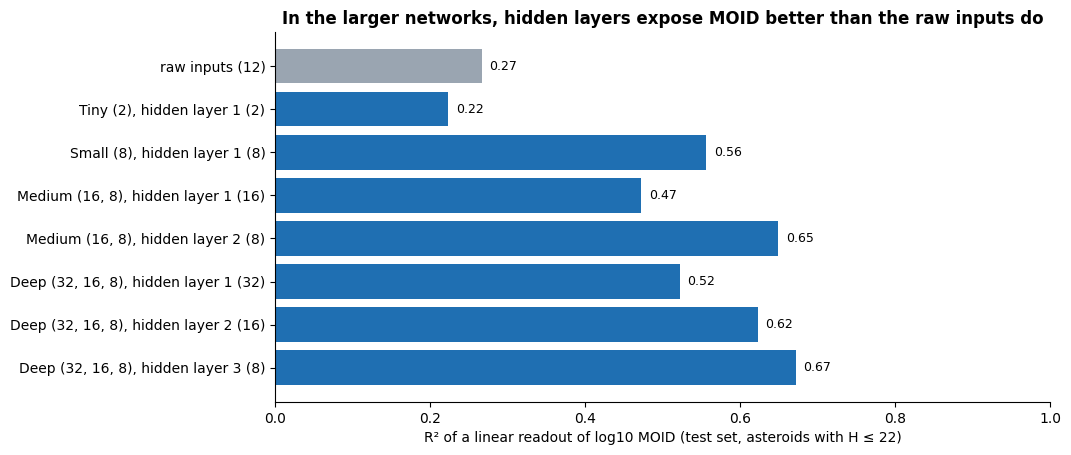

In [29]:
target = np.log10(data["moid"].values)
big_tr = data.loc[idx_train, "H"].values <= 22
big_te = data.loc[idx_test, "H"].values <= 22


def probe(train_feats, test_feats):
    out = {}
    for label, mtr, mte in [("all asteroids", slice(None), slice(None)), ("large asteroids (H ≤ 22)", big_tr, big_te)]:
        model = RidgeCV(alphas=np.logspace(-3, 3, 13)).fit(train_feats[mtr], target[idx_train][mtr])
        out[label] = r2_score(target[idx_test][mte], model.predict(test_feats[mte]))
    return out


some_net = nets["B"]["Tiny (2)"]
probe_rows = [{"representation": "raw inputs (12)", **probe(some_net[:-1].transform(X("B", idx_train)),
                                                         some_net[:-1].transform(X("B", idx_test)))}]
for name, net in nets["B"].items():
    tr_acts, te_acts = hidden_activations(net, X("B", idx_train)), hidden_activations(net, X("B", idx_test))
    for k, (a_tr, a_te) in enumerate(zip(tr_acts, te_acts), start=1):
        probe_rows.append({"representation": f"{name}, hidden layer {k} ({a_tr.shape[1]})", **probe(a_tr, a_te)})
probes = pd.DataFrame(probe_rows)
RESULTS["probes"] = probes.to_dict(orient="records")
display(probes.style.format(precision=3).hide(axis="index"))

fig, ax = plt.subplots(figsize=(10, 4.8))
y_pos = np.arange(len(probes))
ax.barh(y_pos, probes["large asteroids (H ≤ 22)"], color=[SAFE_COLOR] + [POS_COLOR] * (len(probes) - 1))
for yy, v in zip(y_pos, probes["large asteroids (H ≤ 22)"]):
    ax.text(v + 0.01, yy, f"{v:.2f}", va="center", fontsize=9)
ax.set_yticks(y_pos)
ax.set_yticklabels(probes["representation"])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("R² of a linear readout of log10 MOID (test set, asteroids with H ≤ 22)")
ax.set_title("In the larger networks, hidden layers expose MOID better than the raw inputs do")
savefig(fig, "fig15_moid_probe")
plt.show()

From the raw inputs the probe explains 55% of the variance in log MOID over all asteroids, but only 27% for large asteroids (H ≤ 22), which are the ones where MOID decides the label. For large asteroids it is much higher from the hidden layers: 65% from layer 2 of Medium and 67% from layer 3 of Deep. So the bigger networks learned something close to MOID without ever seeing it. Tiny does not (22%), two neurons aren't enough for that. This fits with Vichi and Tommei (2025), who trained a network to predict MOID directly.

### 4.10 Angle encoding and a physics feature

Two extra checks on Experiment B: what happens if the angles are given in raw degrees, and what happens if we add the node distances (Experiment C)?

In [30]:
# (1) Encoding ablation: raw angles in degrees versus sine and cosine pairs
FEATURES["B_raw"] = ["H", "a", "e", "i", "q", "ad", "om", "w", "ma"]
NICE.update({"om": "Ω (deg)", "w": "ω (deg)", "ma": "M (deg)"})
ablation = []
for exp, label in [("B_raw", "raw degrees"), ("B", "sin and cos")]:
    s = sweep[exp] if exp in sweep else depth_sweep(exp)
    sweep[exp] = s
    d = pick_depth(s)
    tree = fit_tree(exp, d)
    ablation.append({"angles": label, "model": f"Decision tree (depth {depth_label(d)})",
                     **score_all(y_test, tree.predict_proba(X(exp, idx_test))[:, 1])})
    r, _ = train_networks(exp, archs={"Medium (16, 8)": (16, 8)})
    ablation.append({"angles": label, "model": "Network Medium (16, 8), mean of 5 seeds",
                     **r[["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc", "avg_precision"]].mean().to_dict()})
ablation = pd.DataFrame(ablation)
RESULTS["angle_ablation"] = ablation.to_dict(orient="records")
display(ablation[["angles", "model", "accuracy", "f1", "roc_auc", "avg_precision"]].style.format(precision=4).hide(axis="index"))

angles,model,accuracy,f1,roc_auc,avg_precision
raw degrees,Decision tree (depth 15),0.9673,0.7237,0.8841,0.5875
raw degrees,"Network Medium (16, 8), mean of 5 seeds",0.9573,0.5448,0.9731,0.6912
sin and cos,Decision tree (depth 15),0.9733,0.7779,0.9042,0.6331
sin and cos,"Network Medium (16, 8), mean of 5 seeds",0.9823,0.8460,0.9954,0.9331


Spearman correlation between node gap and the true MOID: 0.834


experiment,model,f1,avg_precision,roc_auc
B: MOID hidden,Decision tree (depth 15),0.7779,0.6331,0.9042
B: MOID hidden,"Network Medium (16, 8)",0.8460,0.9331,0.9954
B: MOID hidden,"Network Deep (32, 16, 8)",0.8650,0.9423,0.9961
C: MOID hidden + node distances,Decision tree (depth 10),0.8686,0.8603,0.9679
C: MOID hidden + node distances,"Network Medium (16, 8)",0.9082,0.9738,0.9981
C: MOID hidden + node distances,"Network Deep (32, 16, 8)",0.8986,0.9699,0.9977


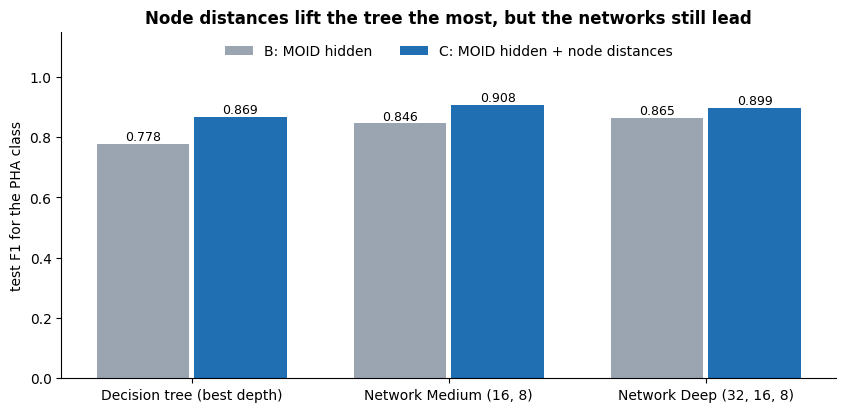

In [31]:
# (2) Experiment C: physics hint
RESULTS["node_gap_vs_moid_spearman"] = spearmanr(data["node_gap"], data["moid"]).correlation
sweep["C"] = depth_sweep("C")
BEST_DEPTH["C"] = pick_depth(sweep["C"])
best_tree["C"] = fit_tree("C", BEST_DEPTH["C"])
runs["C"], nets["C"] = train_networks("C", archs={k: ARCHS[k] for k in ["Medium (16, 8)", "Deep (32, 16, 8)"]})
nn_summary["C"] = summarize(runs["C"])
compare = []
for exp, label in [("B", "B: MOID hidden"), ("C", "C: MOID hidden + node distances")]:
    s = score_all(y_test, best_tree[exp].predict_proba(X(exp, idx_test))[:, 1])
    compare.append({"experiment": label, "model": f"Decision tree (depth {depth_label(BEST_DEPTH[exp])})",
                    "f1": s["f1"], "avg_precision": s["avg_precision"], "roc_auc": s["roc_auc"]})
    for name in ["Medium (16, 8)", "Deep (32, 16, 8)"]:
        row = nn_summary[exp].loc[name]
        compare.append({"experiment": label, "model": f"Network {name}", "f1": row["f1_mean"],
                        "avg_precision": row["avg_precision_mean"], "roc_auc": row["roc_auc_mean"]})
compare = pd.DataFrame(compare)
RESULTS["experiment_C"] = {"best_depth": depth_label(BEST_DEPTH["C"]), "table": compare.to_dict(orient="records"),
                           "sweep": sweep["C"].to_dict(orient="records")}
print(f"Spearman correlation between node gap and the true MOID: {RESULTS['node_gap_vs_moid_spearman']:.3f}")
display(compare.style.format(precision=4).hide(axis="index"))

fig, ax = plt.subplots(figsize=(10, 4.5))
labels = compare["model"].str.replace("Decision tree", "Tree").str.replace("Network ", "")
xpos = np.arange(3)
for k, (exp, color) in enumerate([("B: MOID hidden", SAFE_COLOR), ("C: MOID hidden + node distances", POS_COLOR)]):
    vals = compare.loc[compare["experiment"] == exp, "f1"].values
    ax.bar(xpos + (k - 0.5) * 0.38, vals, width=0.36, color=color, label=exp)
    for xx, v in zip(xpos + (k - 0.5) * 0.38, vals):
        ax.text(xx, v + 0.01, f"{v:.3f}", ha="center", fontsize=9)
ax.set_xticks(xpos)
ax.set_xticklabels(["Decision tree (best depth)", "Network Medium (16, 8)", "Network Deep (32, 16, 8)"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("test F1 for the PHA class")
ax.set_title("Node distances lift the tree the most, but the networks still lead")
ax.legend(frameon=False, loc="upper center", ncol=2)
savefig(fig, "fig16_physics_hint")
plt.show()

With raw degrees the Medium network's F1 drops from 0.846 to 0.545, while the tree only drops from 0.778 to 0.724. A tree can split an angle anywhere, but a network sees 359° and 1° as far apart.

The node gap feature correlates with MOID (ρ = 0.83). With the node features the tree goes from 0.778 to 0.869 F1 (average precision 0.633 to 0.860). The networks improve less (Medium 0.846 to 0.908, Deep 0.865 to 0.899), so the gap between the best network and the tree drops from 0.087 to 0.040. The tree needs the feature given to it, while the network can learn something similar itself.

### 4.11 Famous asteroids

These are out of fold predictions (5 fold cross validation over the whole dataset), so no model is scoring an asteroid it was trained on.

In [32]:
FAMOUS = {"99942": "Apophis", "101955": "Bennu (OSIRIS REx target)", "65803": "Didymos (DART target)",
          "162173": "Ryugu (Hayabusa2 target)", "25143": "Itokawa", "3200": "Phaethon", "4179": "Toutatis",
          "433": "Eros", "1036": "Ganymed", "2024 YR4": "2024 YR4", "2023 DW": "2023 DW"}
best_arch_B = nn_summary["B"]["f1_mean"].idxmax()
case_models = {"Tree A (depth 2)": (DecisionTreeClassifier(max_depth=2, random_state=SEED), "A"),
               "Tiny net A": (make_net((2,), 0), "A"),
               f"Tree B (depth {depth_label(BEST_DEPTH['B'])})": (DecisionTreeClassifier(max_depth=BEST_DEPTH["B"], random_state=SEED), "B"),
               f"Net B {best_arch_B}": (make_net(ARCHS[best_arch_B], 0), "B")}
oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = {name: cross_val_predict(model, data[FEATURES[exp]], data["y"], cv=oof_cv, method="predict_proba")[:, 1]
       for name, (model, exp) in case_models.items()}
RESULTS["oof_scores"] = {name: score_all(data["y"].values, p) for name, p in oof.items()}
famous = data[data["pdes"].isin(FAMOUS)].copy()
cases = famous[["pdes", "H", "moid", "pha"]].copy()
cases.insert(0, "asteroid", famous["pdes"].map(FAMOUS))
for name, p in oof.items():
    cases[name] = p[famous.index]
cases = cases.drop(columns="pdes").sort_values("moid")
RESULTS["cases"] = cases.round(4).to_dict(orient="records")
print("Out of fold P(PHA) for famous asteroids (official label in the pha column)")
display(cases.style.format({"H": "{:.2f}", "moid": "{:.5f}", **{n: "{:.3f}" for n in oof}}).hide(axis="index")
        .background_gradient(cmap="Reds", subset=list(oof), vmin=0, vmax=1))


def explain(tree, exp, pdes):
    row = data.loc[data["pdes"] == pdes, FEATURES[exp]]
    t, names, steps = tree.tree_, FEATURES[exp], []
    for node in tree.decision_path(row).indices:
        if t.children_left[node] == t.children_right[node]:
            counts = t.value[node][0]
            steps.append(f"leaf: P(PHA) = {counts[1] / counts.sum():.3f}")
        else:
            f, thr = names[t.feature[node]], t.threshold[node]
            v = row.iloc[0][f]
            steps.append(f"{NICE[f]} = {v:.4g} {'≤' if v <= thr else '>'} {thr:.4g}")
    return "  →  ".join(steps)


for pdes in ["99942", "2024 YR4", "433"]:
    print(f"{FAMOUS[pdes]:10s} {explain(tree_A2, 'A', pdes)}")

Out of fold P(PHA) for famous asteroids (official label in the pha column)


asteroid,H,moid,pha,Tree A (depth 2),Tiny net A,Tree B (depth 15),"Net B Deep (32, 16, 8)"
Apophis,19.09,0.00011,Y,0.987,0.986,1.000,1.000
Ryugu (Hayabusa2 target),19.55,0.00054,Y,0.987,0.986,1.000,1.000
2023 DW,24.32,0.00054,N,0.000,0.000,0.000,0.000
2024 YR4,23.93,0.00275,N,0.000,0.000,0.000,0.000
Bennu (OSIRIS REx target),20.21,0.00322,Y,0.989,0.990,0.948,1.000
Toutatis,15.29,0.00651,Y,0.989,0.990,1.000,1.000
Itokawa,19.26,0.01305,Y,0.986,0.988,1.000,1.000
Phaethon,14.38,0.01873,Y,0.986,0.988,1.000,0.025
Didymos (DART target),18.11,0.03957,Y,0.986,0.988,0.000,1.000
Eros,10.40,0.14880,N,0.000,0.000,0.000,0.000


Apophis    H = 19.09 ≤ 22.04  →  MOID = 0.0001079 ≤ 0.05002  →  leaf: P(PHA) = 0.987
2024 YR4   H = 23.93 > 22.04  →  H = 23.93 > 22.12  →  leaf: P(PHA) = 0.000
Eros       H = 10.4 ≤ 22.04  →  MOID = 0.1488 > 0.05002  →  leaf: P(PHA) = 0.000


With MOID available, the tree and the Tiny network get all of these right. 2024 YR4 is a good example of what the label means. In February 2025 it briefly had about a 3% chance of hitting Earth in 2032 (NASA Science Editorial Team, 2025a, 2025b), but it is not a PHA because H = 23.93 (about 60 m wide, NASA, n.d.). The tree rejects it at the very first split.

With MOID hidden, the tree misses Didymos (the DART target) and the Deep network misses Phaethon (0.025), which has a very eccentric orbit (e = 0.89, q = 0.14 au). They make different mistakes, so combining them could help.

### 4.12 All results

In [33]:
board = []
for exp, label in [("A", "A: MOID available"), ("B", "B: MOID hidden")]:
    s = score_all(y_test, best_tree[exp].predict_proba(X(exp, idx_test))[:, 1])
    board.append({"experiment": label, "model": f"Decision tree (depth {depth_label(BEST_DEPTH[exp])})",
                  **{k: f"{s[k]:.4f}" for k in ["accuracy", "balanced_accuracy", "f1", "roc_auc", "avg_precision"]}})
    p = pretty(nn_summary[exp])
    for name in ARCHS:
        board.append({"experiment": label, "model": f"Network {name}",
                      **{k: p.loc[name, k] for k in ["accuracy", "balanced_accuracy", "f1", "roc_auc", "avg_precision"]}})
board = pd.DataFrame(board)
board.to_csv(RES_DIR / "scoreboard.csv", index=False)
RESULTS["scoreboard"] = board.to_dict(orient="records")
RESULTS["runtime_minutes"] = (time.time() - NOTEBOOK_START) / 60
(RES_DIR / "results.json").write_text(json.dumps(RESULTS, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
print(f"Saved results/results.json and results/scoreboard.csv. Runtime so far: {RESULTS['runtime_minutes']:.1f} minutes.")
board.style.hide(axis="index")

Saved results/results.json and results/scoreboard.csv. Runtime so far: 5.6 minutes.


experiment,model,accuracy,balanced_accuracy,f1,roc_auc,avg_precision
A: MOID available,Decision tree (depth 2),0.9987,0.9938,0.9892,0.9966,0.9825
A: MOID available,Network Tiny (2),0.9925 ± 0.0108,0.9650 ± 0.0491,0.9364 ± 0.0917,0.9978 ± 0.0042,0.9667 ± 0.0683
A: MOID available,Network Small (8),0.9976 ± 0.0002,0.9875 ± 0.0022,0.9793 ± 0.0017,0.9999 ± 0.0000,0.9980 ± 0.0001
A: MOID available,"Network Medium (16, 8)",0.9968 ± 0.0003,0.9864 ± 0.0026,0.9734 ± 0.0026,0.9998 ± 0.0000,0.9974 ± 0.0004
A: MOID available,"Network Deep (32, 16, 8)",0.9956 ± 0.0004,0.9787 ± 0.0032,0.9626 ± 0.0030,0.9997 ± 0.0001,0.9955 ± 0.0008
B: MOID hidden,Decision tree (depth 15),0.9733,0.8857,0.7779,0.9042,0.6331
B: MOID hidden,Network Tiny (2),0.9419 ± 0.0028,0.5211 ± 0.0471,0.0655 ± 0.1464,0.9458 ± 0.0085,0.4047 ± 0.0413
B: MOID hidden,Network Small (8),0.9652 ± 0.0051,0.7848 ± 0.0411,0.6621 ± 0.0636,0.9840 ± 0.0055,0.7857 ± 0.0656
B: MOID hidden,"Network Medium (16, 8)",0.9823 ± 0.0031,0.9077 ± 0.0213,0.8460 ± 0.0290,0.9954 ± 0.0010,0.9331 ± 0.0169
B: MOID hidden,"Network Deep (32, 16, 8)",0.9840 ± 0.0030,0.9272 ± 0.0129,0.8650 ± 0.0249,0.9961 ± 0.0010,0.9423 ± 0.0149


## 5 Discussion

### 5.1 Answers to the questions

1. Yes, the tree found the rule at depth 2. Depth 1 underfits (all bias), and going deeper than 2 only adds variance from fitting the noisy labels.
2. No, nodes at the same level split on different attributes. CART picks the best split for each node's own subset of data, and the subsets are different. For example, large asteroids need a MOID split but small ones don't.
3. When the label is just two thresholds, network size doesn't matter much. When MOID is hidden, the networks need 2 or 3 hidden layers.
4. In the Tiny network the weights match the tree directly, one neuron per split. In the bigger networks the raw weights are spread out, so permutation importance is a better way to compare them with the tree.

### 5.2 Trees vs networks

The tree was better at the threshold rule and the networks were better at the orbit geometry. This makes sense since a tree only makes straight cuts on one feature at a time, while a network builds smooth functions. It also fits Grinsztajn et al. (2022), who found that trees do well on irregular patterns in tabular data while networks tend toward smooth solutions. How the inputs were encoded also mattered: circular angles helped the network much more than the tree, and the physics feature helped the tree more than the networks.

### 5.3 Limitations

* Experiment A is basically label leakage, since the label is computed from MOID and H. That's why we also ran Experiment B.
* In real life MOID is computed from the orbit anyway, so B is more of a test than a real use case.
* We used one train/test split and a 0.5 threshold. The out of fold F1 scores were close to the test scores (tree A 0.989, Tiny 0.978, tree B 0.785, Deep B 0.851), but we did not tune the threshold or compute confidence intervals for the trees.
* The catalog has discovery bias, since asteroids that come close to Earth are easier to find.
* Weight based importance is only approximate, and correlated inputs (q, a, e, Q) can share importance.

## 6 Conclusion

A depth 2 decision tree recovered NASA's PHA rule from the data, and a network with 2 hidden neurons learned the same rule with one neuron per condition. Making the tree deeper than 2 only added variance. Without MOID, the networks with 2 or 3 hidden layers did better than the tree (F1 0.865 vs 0.778) and partly learned MOID in their hidden layers. The edge weights matched the tree in the small network but not as well in the bigger ones.

## 7 References

APA style. Titles are written as published.

Bora, C. A., Kushvah, B. S., Mouli, G. C., & Yousuf, S. (2024). Temporal trends in asteroid behaviour: A machine learning and N-body integration approach. *Monthly Notices of the Royal Astronomical Society, 534*(1), 415 to 430. https://doi.org/10.1093/mnras/stae2083

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5 to 32. https://doi.org/10.1023/A:1010933404324

Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (2017). *Classification and regression trees*. Chapman and Hall/CRC. https://doi.org/10.1201/9781315139470 (Original work published 1984)

Center for Near Earth Object Studies. (n.d.). *NEO groups*. NASA Jet Propulsion Laboratory. Retrieved November 14, 2026, from https://cneos.jpl.nasa.gov/about/neo_groups.html

Domingos, P. (2000). A unified bias-variance decomposition for zero-one and squared loss. In *Proceedings of the Seventeenth National Conference on Artificial Intelligence* (pp. 564 to 569). AAAI Press.

Fisher, A., Rudin, C., & Dominici, F. (2019). All models are wrong, but many are useful: Learning a variable's importance by studying an entire class of prediction models simultaneously. *Journal of Machine Learning Research, 20*(177), 1 to 81. https://jmlr.org/papers/v20/18-760.html

Garson, G. D. (1991). Interpreting neural-network connection weights. *AI Expert, 6*(4), 46 to 51.

Geman, S., Bienenstock, E., & Doursat, R. (1992). Neural networks and the bias/variance dilemma. *Neural Computation, 4*(1), 1 to 58. https://doi.org/10.1162/neco.1992.4.1.1

Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *Advances in Neural Information Processing Systems, 35*, 507 to 520.

Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The elements of statistical learning* (2nd ed.). Springer. https://doi.org/10.1007/978-0-387-84858-7

Hefele, J. D., Bortolussi, F., & Portegies Zwart, S. (2020). Identifying Earth-impacting asteroids using an artificial neural network. *Astronomy and Astrophysics, 634*, A45. https://doi.org/10.1051/0004-6361/201935983

Hornik, K., Stinchcombe, M., & White, H. (1989). Multilayer feedforward networks are universal approximators. *Neural Networks, 2*(5), 359 to 366. https://doi.org/10.1016/0893-6080(89)90020-8

Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *3rd International Conference on Learning Representations (ICLR 2015)*. https://arxiv.org/abs/1412.6980

LeNail, A. (2019). NN-SVG: Publication-ready neural network architecture schematics. *Journal of Open Source Software, 4*(33), 747. https://doi.org/10.21105/joss.00747

Malakouti, S. M., Menhaj, M. B., & Suratgar, A. A. (2023). Machine learning techniques for classifying dangerous asteroids. *MethodsX, 11*, 102337. https://doi.org/10.1016/j.mex.2023.102337

NASA. (n.d.). *2024 YR4 facts*. NASA Science. Retrieved November 14, 2026, from https://science.nasa.gov/solar-system/asteroids/2024-yr4-facts/

NASA Jet Propulsion Laboratory. (2021). *SBDB query API* (Version 1.0) [API documentation]. Retrieved November 14, 2026, from https://ssd-api.jpl.nasa.gov/doc/sbdb_query.html

NASA Science Editorial Team. (2018, February 15). *Five years after the Chelyabinsk meteor, NASA leads efforts in planetary defense*. NASA Science. https://science.nasa.gov/science-research/planetary-science/planetary-defense/five-years-after-the-chelyabinsk-meteor-nasa-leads-efforts-in-planetary-defense/

NASA Science Editorial Team. (2025a, February 19). *Dark skies bring new observations of asteroid 2024 YR4, lower impact probability*. NASA Science, Planetary Defense Blog. https://science.nasa.gov/blogs/planetary-defense/2025/02/19/dark-skies-bring-new-observations-of-asteroid-2024-yr4-lower-impact-probability/

NASA Science Editorial Team. (2025b, February 24). *Latest calculations conclude asteroid 2024 YR4 now poses no significant threat to Earth in 2032 and beyond*. NASA Science, Planetary Defense Blog. https://science.nasa.gov/blogs/planetary-defense/2025/02/24/latest-calculations-conclude-asteroid-2024-yr4-now-poses-no-significant-threat-to-earth-in-2032-and-beyond/

Olden, J. D., & Jackson, D. A. (2002). Illuminating the "black box": A randomization approach for understanding variable contributions in artificial neural networks. *Ecological Modelling, 154*, 135 to 150. https://doi.org/10.1016/S0304-3800(02)00064-9

Olden, J. D., Joy, M. K., & Death, R. G. (2004). An accurate comparison of methods for quantifying variable importance in artificial neural networks using simulated data. *Ecological Modelling, 178*, 389 to 397. https://doi.org/10.1016/j.ecolmodel.2004.03.013

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825 to 2830. https://jmlr.org/papers/v12/pedregosa11a.html

Popova, O. P., Jenniskens, P., Emel'yanenko, V., Kartashova, A., Biryukov, E., Khaibrakhmanov, S., Shuvalov, V., Rybnov, Y., Dudorov, A., Grokhovsky, V. I., Badyukov, D. D., Yin, Q. Z., Gural, P. S., Albers, J., Granvik, M., Evers, L. G., Kuiper, J., Kharlamov, V., Solovyov, A., . . . Mikouchi, T. (2013). Chelyabinsk airburst, damage assessment, meteorite recovery, and characterization. *Science, 342*(6162), 1069 to 1073. https://doi.org/10.1126/science.1242642

Thomas, C. A., Naidu, S. P., Scheirich, P., Moskovitz, N. A., Pravec, P., Chesley, S. R., Rivkin, A. S., Osip, D. J., Lister, T. A., Benner, L. A. M., Brozović, M., Contreras, C., Morrell, N., Rożek, A., Kušnirák, P., Hornoch, K., Mages, D., Taylor, P. A., Seymour, A. D., . . . Agrusa, H. F. (2023). Orbital period change of Dimorphos due to the DART kinetic impact. *Nature, 616*(7957), 448 to 451. https://doi.org/10.1038/s41586-023-05805-2

Vichi, V., & Tommei, G. (2025). Exploring the potential of neural networks in early detection of potentially hazardous near-earth objects. *Celestial Mechanics and Dynamical Astronomy, 137*(3), 17. https://doi.org/10.1007/s10569-025-10248-0

## Appendix: reproducibility

In [34]:
import platform
import sys
print(f"Python {sys.version.split()[0]} on {platform.system()} {platform.machine()}")
print(f"numpy {np.__version__}, pandas {pd.__version__}, sklearn {sklearn.__version__}, matplotlib {mpl.__version__}")
print(f"Data snapshot: {meta['retrieved_utc']}, {len(raw):,} rows, file {CSV_PATH}")
print(f"Total runtime: {(time.time() - NOTEBOOK_START) / 60:.1f} minutes")

Python 3.10.11 on Darwin arm64
numpy 2.0.0, pandas 2.3.3, sklearn 1.7.2, matplotlib 3.10.9
Data snapshot: 2026-11-14 19:27:07 UTC, 43,090 rows, file data/neo_asteroids_sbdb.csv
Total runtime: 5.6 minutes
